# Import và đọc ảnh

In [1]:
import pandas as pd
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, Dense, Dropout, Flatten, Reshape, BatchNormalization
from keras.models import Model
from keras.callbacks import EarlyStopping
from keras.regularizers import l2
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

2026-06-22 12:28:08.515217: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1782131288.759360      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1782131288.828548      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1782131289.383216      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782131289.383262      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782131289.383267      58 computation_placer.cc:177] computation placer alr

In [2]:
# Hàm đọc ảnh từ những split cho vào
# Trả về ảnh và nhãn tương ứng dưới dạng: ma trận [số ảnh, 64, 64] và ma trận nồng độ [số ảnh,2]
# def read_img_from_splits(df, split_list, folder):
#     # Chỉ lấy các dòng thuộc list split đã chọn
#     df_part = df[df['split_number'].isin(split_list)]
#     images = []

#     # Lặp qua từng hàng trong dataframe để đọc ảnh và lấy nhãn tương ứng 
#     for index, row in df_part.iterrows():
#         img_path = folder + '/split' + str(row['split_number']) + '/' + str(row['image_name'])
#         img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)  # Đọc ảnh xám
#         img = np.array(img).astype('float32') / 255.0  # Chuẩn hóa dữ liệu ảnh
#         images.append(img)

#     # Chuyển đổi danh sách thành numpy arrays
#     df_part.loc[:,["Image"]] = images
#     images = np.array(images)

#     # df_part.loc[:,['is_abnormal']] = 1 - df_part.loc[:, ['is_normal']]
    
#     return images, df_part[['CO2 conc (ppm)', 'Ethylene conc (ppm)']], df_part

import ast
import cv2
import numpy as np
import pandas as pd


def has_sensor_failure(abnormal_detail):

    if pd.isna(abnormal_detail):
        return False

    if isinstance(abnormal_detail, str):
        abnormal_detail = ast.literal_eval(abnormal_detail)

    if not isinstance(abnormal_detail, dict):
        return False

    return abnormal_detail.get("Sensor Failure", 0) > 0

def read_img_from_splits(
    df,
    split_list,
    folder,
    exclude_sensor_failure=False
):

    df_part = (
        df[df["split_number"].isin(split_list)]
        .copy()
        .reset_index(drop=True)
    )

    # loại mọi ảnh có Sensor Failure trong abnormal_detail
    if (
        exclude_sensor_failure
        and "abnormal_detail" in df_part.columns
    ):
        mask = ~df_part["abnormal_detail"].apply(
            has_sensor_failure
        )

        print(
            f"Removed {(~mask).sum()} images "
            f"containing Sensor Failure"
        )

        df_part = (
            df_part[mask]
            .copy()
            .reset_index(drop=True)
        )

    images = []

    for _, row in df_part.iterrows():

        img_path = (
            f"{folder}/split{row['split_number']}/"
            f"{row['image_name']}"
        )

        img = cv2.imread(
            img_path,
            cv2.IMREAD_GRAYSCALE
        )

        img = img.astype(np.float32) / 255.0

        images.append(img)

    df_part["Image"] = images

    images = np.stack(images)

    return (
        images,
        df_part[
            ["CO2 conc (ppm)", "Ethylene conc (ppm)"]
        ],
        df_part
    )
    
def extract_xy_keep_normal(df, abnormal_ratio=0.2, random_state=42):
    """
    Giữ toàn bộ normal, sample abnormal theo tỷ lệ mong muốn

    abnormal_ratio = abnormal / (normal + abnormal)
    """

    df = df.copy()
    df.loc[:, 'is_abnormal'] = 1 - df.loc[:, 'is_normal']

    df_normal = df[df["is_abnormal"] == 0]
    df_ab     = df[df["is_abnormal"] == 1]

    n_normal = len(df_normal)

    # ===== Tính số abnormal cần =====
    if abnormal_ratio == 0:
        n_ab_sample = 0
    else:
        n_ab_sample = int(n_normal * abnormal_ratio / (1 - abnormal_ratio))

    # ===== Sample abnormal =====
    if len(df_ab) > 0:
        df_ab_sampled = df_ab.sample(
            n=min(n_ab_sample, len(df_ab)),
            random_state=random_state
        )
        df_balanced = pd.concat([df_normal, df_ab_sampled])
    else:
        df_balanced = df_normal

    # shuffle
    # df_balanced = df_balanced.sample(frac=1, random_state=random_state)

    # ===== Extract =====
    X = df_balanced["Image"].tolist()
    y = df_balanced["is_abnormal"].tolist()

    X = np.expand_dims(np.array(X), axis=-1)
    y = np.array(y)

    df_balanced["Image"] = list(X)
    return X, y, df_balanced

In [3]:
dataset_path = "/kaggle/input/datasets/dangthithuha/newcopl"
df_aug = pd.read_csv(f'{dataset_path}/augmented_abnormal/image_labels.csv')
df_ab = pd.read_csv(f'{dataset_path}/augmented_abnormal/image_labels.csv')

split_test = [5]
split_train = [i for i in range(1,6) if i not in split_test] 

# Đọc các ảnh bình thường, cho split 1 2 3 4 là X_train
# Đọc split 5 mục abnormal để thành x_test_normal
_, _, df_train = read_img_from_splits(df_aug, split_train, 
                                      folder=f"{dataset_path}/augmented_abnormal",
                                     exclude_sensor_failure=False)
_, _, df_test = read_img_from_splits(df_ab, split_test, 
                                     folder=f"{dataset_path}/augmented_abnormal",
                                     exclude_sensor_failure=False)
print("Df train len", len(df_train))
print("Df test len", len(df_test))
# ===== Train =====
X_train, y_train, df_train = extract_xy_keep_normal(
    df_train,
    abnormal_ratio=0.2
)

# ===== Test =====
X_test, y_test, df_test = extract_xy_keep_normal(
    df_test,
    abnormal_ratio=0.2
)

print("Train shape:", X_train.shape, y_train.shape)
print("Test shape :", X_test.shape, y_test.shape)

print("\nSample train y:", y_train[:10])
print("Sample test y :", y_test[:10])

# distribution
def print_dist(y, name):
    unique, counts = np.unique(y, return_counts=True)
    print(f"{name} distribution:", dict(zip(unique, counts)))

print_dist(y_train, "Train")
print_dist(y_test, "Test")

# Huấn luyện mô hình Autoencoder
X_train_normal = X_train[y_train == 0]
X_test_normal = X_test[y_test == 0]

print(len(X_train_normal))
print(df_train[df_train.is_abnormal==0].shape)
print(df_train["dominant_abnormal"].value_counts())

Df train len 2720
Df test len 670
Train shape: (1700, 128, 128, 1) (1700,)
Test shape : (418, 128, 128, 1) (418,)

Sample train y: [0 0 0 0 0 0 0 0 0 0]
Sample test y : [0 0 0 0 0 0 0 0 0 0]
Train distribution: {np.int64(0): np.int64(1360), np.int64(1): np.int64(340)}
Test distribution: {np.int64(0): np.int64(335), np.int64(1): np.int64(83)}
1360
(1360, 10)
dominant_abnormal
Abrupt Change     90
Random Patch      64
Signal Drift      64
Noise             62
Sensor Failure    60
Name: count, dtype: int64


Train shape: (1693, 128, 128, 1) (1693,)
Test shape : (425, 128, 128, 1) (425,)

Sample train y: [0 1 1 0 1 0 1 1 0 0]
Sample test y : [1 0 0 0 1 1 0 0 1 0]
Train distribution: {0: 1355, 1: 338}
Test distribution: {0: 340, 1: 85}
1355
(1355, 10)


In [117]:
X_test, y_test, df_test = extract_xy_keep_normal(
    df_test,
    abnormal_ratio=1.0   # lấy toàn bộ abnormal
)

print("Test shape :", X_test.shape, y_test.shape)

print_dist(y_test, "Test")


ZeroDivisionError: float division by zero

# Sắp xếp ảnh

### Normal

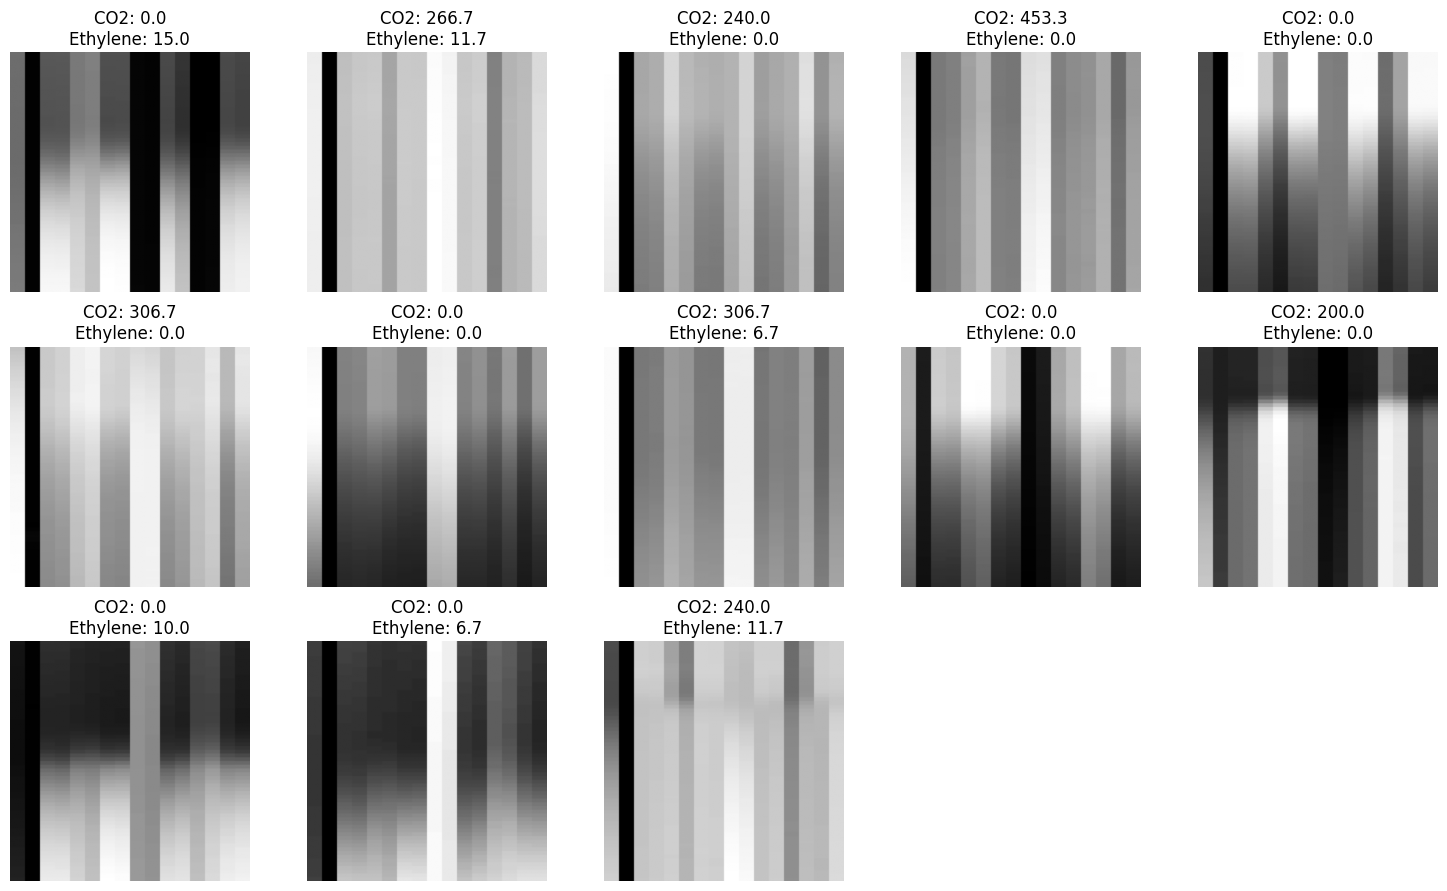

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math

columns = 5

image_data_normal = df_train[
    df_train["is_abnormal"] == 0
][["Image", "CO2 conc (ppm)", "Ethylene conc (ppm)"]]

# ===== random 1% =====
sample_ratio = 0.01
n_show = max(1, int(len(image_data_normal) * sample_ratio))

image_data_normal = image_data_normal.sample(
    n=n_show,
    random_state=42
).reset_index(drop=True)

# ===== plot =====
num_images = len(image_data_normal)
rows = math.ceil(num_images / columns)
plt.figure(figsize=(15, rows * 3))
for i in range(num_images):
    image, co2, ethylene = image_data_normal.iloc[i]
    plt.subplot(rows, columns, i + 1)
    plt.imshow(image.squeeze(), cmap='gray')
    plt.axis('off')
    plt.title(
        f"CO2: {co2:.1f}\nEthylene: {ethylene:.1f}")

plt.tight_layout()
plt.show()

### Abnomal

In [5]:
# import matplotlib.pyplot as plt
# import math

# # Số cột mong muốn trong lưới hiển thị
# columns = 5

# # Tạo danh sách chứa tổng nồng độ (CO2 + Ethylene) và chỉ số ảnh từ tập x_test_abnormal
# image_data_abnormal = [(x_test_abnormal[i], y_abnormal_co2[i], y_abnormal_ethylene[i], y_abnormal_co2[i] + y_abnormal_ethylene[i]) 
#                        for i in range(len(x_test_abnormal))]

# # Sắp xếp danh sách dựa theo tổng nồng độ (CO2 + Ethylene)
# image_data_sorted_abnormal = sorted(image_data_abnormal, key=lambda x: x[3])  # Sắp xếp theo tổng nồng độ

# # Hiển thị ảnh theo thứ tự đã sắp xếp
# num_images = len(image_data_sorted_abnormal)
# rows = math.ceil(num_images / columns)  # Tính số hàng cần thiết dựa trên số cột

# plt.figure(figsize=(15, rows * 3))  # Kích thước figure tổng thể
# for i in range(num_images):
#     image, co2, ethylene, total_concentration = image_data_sorted_abnormal[i]
#     plt.subplot(rows, columns, i + 1)  # Tạo các lưới con
#     plt.imshow(image.squeeze(), cmap='gray')  # Hiển thị ảnh
#     plt.axis('off')  # Tắt trục tọa độ
#     plt.title(f"CO2: {co2:.1f} ppm\nEthylene: {ethylene:.1f} ppm\nTotal: {total_concentration:.1f} ppm")  # Hiển thị CO2, Ethylene và tổng nồng độ

# plt.tight_layout()  # Sắp xếp gọn các ảnh
# plt.show()

In [6]:
# import matplotlib.pyplot as plt
# import math

# # Số cột mong muốn trong lưới hiển thị
# columns = 5

# # Hiển thị toàn bộ ảnh từ tập huấn luyện (CO2 < 300)
# num_images = len(X_train)
# rows = math.ceil(num_images / columns)  # Tính số hàng cần thiết dựa trên số cột

# plt.figure(figsize=(15, rows * 3))  # Kích thước figure tổng thể
# for i in range(num_images):
#     plt.subplot(rows, columns, i + 1)  # Tạo các lưới con
#     plt.imshow(X_train[i].squeeze(), cmap='gray')  # Hiển thị ảnh, squeeze để loại bỏ chiều đơn lẻ
#     plt.axis('off')  # Tắt trục tọa độ
#     plt.title(f"CO2: {y_train_co2[i]:.1f} ppm\nEthylene: {y_train_ethylene[i]:.1f} ppm")  # Hiển thị CO2 và Ethylene

# plt.tight_layout()  # Sắp xếp gọn các ảnh
# plt.show()

# # Hiển thị toàn bộ ảnh từ tập abnormal (CO2 >= 300)
# num_images = len(x_test_abnormal)
# rows = math.ceil(num_images / columns)  # Tính số hàng cần thiết dựa trên số cột

# plt.figure(figsize=(15, rows * 3))  # Kích thước figure tổng thể
# for i in range(num_images):
#     plt.subplot(rows, columns, i + 1)  # Tạo các lưới con
#     plt.imshow(x_test_abnormal[i].squeeze(), cmap='gray')  # Hiển thị ảnh
#     plt.axis('off')  # Tắt trục tọa độ
#     plt.title(f"CO2: {y_abnormal_co2[i]:.1f} ppm\nEthylene: {y_abnormal_ethylene[i]:.1f} ppm")  # Hiển thị CO2 và Ethylene

# plt.tight_layout()  # Sắp xếp gọn các ảnh
# plt.show()

In [5]:
X_tam=X_train_normal
X_tam.shape


(1360, 128, 128, 1)

# Autoencoder

In [6]:
%%time
# Kích thước:
input_img = Input(shape=(128, 128, 1))  # Đầu vào ảnh có kích thước 128x128
stride = 2

# Encoder
x = Conv2D(32, (5, 5), activation='relu', padding='same', strides=stride)(input_img)  # tensor 64x64x128
x = Conv2D(16, (5, 5), activation='relu', padding='same', strides=stride)(x)  # tensor 32x32x64
x = Conv2D(8, (5, 5), activation='relu', padding='same', strides=stride)(x)  # tensor 16x16x32
x = Conv2D(8, (5, 5), activation='relu', padding='same', strides=stride)(x)  # tensor 16x16x32
x = MaxPooling2D((2, 2), padding='same')(x)  # tensor 8x8x32 (giảm kích thước với MaxPooling)
x = Flatten()(x)  # Vector 1D tensor với 8*8*32=2048 phần tử

# Tạo mô hình Encoder
encoder = Model(input_img, x)

# Decoder
x = Reshape((4, 4, 8))(x)  # Chuyển đổi từ vector 1D thành tensor 3D

x = UpSampling2D((2, 2))(x)  # tensor 16x16x32 (tăng kích thước)
x = Conv2D(8, (5, 5), activation='relu', padding='same')(x)  # tensor 32x32x32

x = UpSampling2D((2, 2))(x)  # tensor 16x16x32 (tăng kích thước)
x = Conv2D(8, (5, 5), activation='relu', padding='same')(x)  # tensor 32x32x32
x = UpSampling2D((2, 2))(x)  # tensor 16x16x32 (tăng kích thước)
x = Conv2D(16, (5, 5), activation='relu', padding='same')(x)  # tensor 64x64x64
x = UpSampling2D((2, 2))(x)  # tensor 16x16x32 (tăng kích thước)
x = Conv2D(32, (5, 5), activation='relu', padding='same')(x)  # tensor 128x128x128
x = UpSampling2D((2, 2))(x)  # tensor 16x16x32 (tăng kích thước)
decoded = Conv2D(1, (5, 5), activation='sigmoid', padding='same')(x)  # tensor 128x128x1 (kết quả cuối cùng là ảnh 128x128x1)

# Xây dựng mô hình Autoencoder
autoencoder = Model(input_img, decoded)
autoencoder.summary()  # Hiển thị kiến trúc 
autoencoder.compile(optimizer='adam', loss='mse')

callback = EarlyStopping(monitor='loss', patience=30)
autoencoder.fit(X_train_normal, X_train_normal,
                epochs=20,
                batch_size=16,
                shuffle=True,
                validation_data=(X_test_normal, X_test_normal),
                verbose=2,
                callbacks=[callback])

2026-06-22 12:30:11.630779: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 16)     │        12,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 8)      │         3,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 8)        │         1,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 8, 8, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 8)        │         1,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 16, 16, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 8)      │         1,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 32, 32, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 16)     │         3,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 32)     │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_4 (UpSampling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 128, 128, 1)    │           801 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,529 (150.50 KB)

 Trainable params: 38,529 (150.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
85/85 - 54s - 640ms/step - loss: 0.0384 - val_loss: 0.0165
Epoch 2/20
85/85 - 49s - 574ms/step - loss: 0.0095 - val_loss: 0.0052
Epoch 3/20
85/85 - 49s - 572ms/step - loss: 0.0048 - val_loss: 0.0047
Epoch 4/20
85/85 - 50s - 586ms/step - loss: 0.0033 - val_loss: 0.0033
Epoch 5/20
85/85 - 48s - 570ms/step - loss: 0.0026 - val_loss: 0.0029
Epoch 6/20
85/85 - 50s - 588ms/step - loss: 0.0024 - val_loss: 0.0027
Epoch 7/20
85/85 - 49s - 576ms/step - loss: 0.0020 - val_loss: 0.0017
Epoch 8/20
85/85 - 48s - 570ms/step - loss: 0.0018 - val_loss: 0.0017
Epoch 9/20
85/85 - 48s - 570ms/step - loss: 0.0015 - val_loss: 0.0028
Epoch 10/20
85/85 - 48s - 567ms/step - loss: 0.0015 - val_loss: 0.0018
Epoch 11/20
85/85 - 48s - 564ms/step - loss: 0.0014 - val_loss: 0.0013
Epoch 12/20
85/85 - 48s - 566ms/step - loss: 0.0015 - val_loss: 0.0027
Epoch 13/20
85/85 - 48s - 569ms/step - loss: 0.0014 - val_loss: 0.0012
Epoch 14/20
85/85 - 49s - 573ms/step - loss: 0.0011 - val_loss: 0.0012
Epoch 15/20
85/

## Evaluate training stage

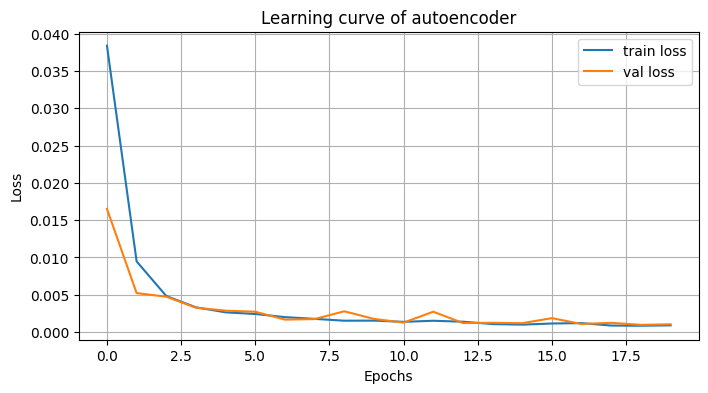

In [7]:
plt.figure(figsize=(8, 4))

plt.plot(
    autoencoder.history.history['loss'], 
    label="train loss"
)

plt.plot(
    autoencoder.history.history['val_loss'], 
    label="val loss"
)

plt.title("Learning curve of autoencoder")

# Tên 2 trục
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

## Predict

In [21]:
def create_image_dataframe_from_df(
    model,
    encoder,
    train_df,
    test_df,
    image_col='Image'
):
    """
    Giữ nguyên toàn bộ cột của df gốc.
    Chỉ bổ sung:
        reconstructed_image
        latent_vector
        is_test
    """

    dfs = []

    for df_src, is_test in [
        (train_df, 0),
        (test_df, 1)
    ]:

        df_tmp = df_src.copy()

        X = np.stack(df_tmp[image_col].values)

        print(
            f"Predicting {'test' if is_test else 'train'} "
            f"({len(df_tmp)} samples)"
        )

        reconstructed = model.predict(X, verbose=0)
        latent = encoder.predict(X, verbose=0)

        df_tmp['original_image'] = list(X)
        df_tmp['reconstructed_image'] = list(reconstructed)
        df_tmp['latent_vector'] = list(latent)

        df_tmp['is_test'] = is_test

        dfs.append(df_tmp)

    return pd.concat(dfs, ignore_index=True)

image_df = create_image_dataframe_from_df(
    autoencoder,
    encoder,
    df_train,
    df_test
)
image_df['is_abnormal'] = 1 - image_df['is_normal']

image_df['True_Label'] = np.where(
    image_df['is_normal'] == 1,
    'Normal',
    'Abnormal'
)
image_df['label'] = np.select(
    [
        (image_df['is_test'] == 0) & (image_df['is_normal'] == 1),
        (image_df['is_test'] == 0) & (image_df['is_normal'] == 0),
        (image_df['is_test'] == 1) & (image_df['is_normal'] == 1),
        (image_df['is_test'] == 1) & (image_df['is_normal'] == 0),
    ],
    [
        'norm_train',
        'ab_train',
        'norm_test',
        'ab_test'
        ],
    default='Unknown'
)

print(image_df.shape)

Predicting train (1700 samples)
Predicting test (418 samples)
(2118, 16)


In [9]:

print(image_df['dominant_abnormal'].value_counts(dropna=False))
print(len(image_df[image_df['dominant_abnormal'].isna() & (image_df['is_test']==0)]))
# print(image_df[(image_df['dominant_abnormal'] != np.nan) & (image_df['is_test'] == 0)])

dominant_abnormal
NaN               1695
Abrupt Change      106
Signal Drift        85
Random Patch        81
Sensor Failure      76
Noise               75
Name: count, dtype: int64
1360


## Threshold helpers

In [37]:
# ========================================================================================
# THRESHOLD-BASED ANOMALY DETECTION (CONSOLIDATED)
# ========================================================================================
# Các function gọn gàng, không lặp lại logic:
# 1. compute_error_once: Tính error từ ảnh, xử lý NaN/inf
# 2. run_threshold_experiments: Chạy toàn bộ experiments với nhiều alphas
# 3. evaluate_with_fixed_alpha: Evaluate một error function với alpha cố định
# ========================================================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, r2_score, confusion_matrix
)

def compute_error_once(image_df, cal_error_function):
    """
    Tính error một lần từ toàn bộ DataFrame.
    
    ⚠️ QUAN TRỌNG: Xử lý NaN/inf bằng median của BỘ DỮ LIỆU ĐÓ
    Nếu tính error từ subset khác nhau (train vs test), median khác nhau → error khác
    
    Args:
        image_df: DataFrame có 'original_image' và 'reconstructed_image'
        cal_error_function: Hàm tính error (MSE, MADn, MSD)
    
    Returns:
        pd.Series: Error values
    """
    original_images_list = image_df['original_image'].tolist()
    reconstructed_images_list = image_df['reconstructed_image'].tolist()

    errors = cal_error_function(original_images_list, reconstructed_images_list)
    
    # Xử lý inf/nan
    errors = pd.Series(np.array(errors, dtype=np.float64))
    errors.replace([np.inf, -np.inf], np.nan, inplace=True)
    errors = errors.fillna(errors.median())
    
    return errors


def plot_error_distribution(eval_df, thresholds, title="Error Distribution"):
    """
    Vẽ KDE + CDF của error với các đường threshold.
    """
    mean_error = thresholds['mean']
    threshold_min = thresholds['threshold_min']
    threshold_max = thresholds['threshold_max']
    
    #unique_labels = eval_df['label'].unique()
    unique_labels = ['norm_test', 'ab_test']
    palette = sns.color_palette("tab10", n_colors=len(unique_labels))
    color_map = dict(zip(unique_labels, palette))
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # KDE
    ax_kde = axes[0]
    for label in unique_labels:
        data = eval_df[eval_df['label'] == label]['error']
        sns.kdeplot(data, label=f'KDE ({label})', color=color_map[label], 
                   fill=True, alpha=0.5, ax=ax_kde)
    
    ax_kde.axvline(mean_error, color='g', linestyle='--', linewidth=2, label=f'Mean ({mean_error:.4f})')
    ax_kde.axvline(threshold_min, color='r', linestyle='--', linewidth=2, label=f'Min ({threshold_min:.4f})')
    ax_kde.axvline(threshold_max, color='r', linestyle='--', linewidth=2, label=f'Max ({threshold_max:.4f})')
    ax_kde.set_title(f'{title} - KDE')
    ax_kde.set_xlabel('Error')
    ax_kde.set_ylabel('Density')
    ax_kde.legend(loc='upper right')
    ax_kde.grid(True, alpha=0.6)
    
    # CDF
    ax_cdf = axes[1]
    for label in unique_labels:
        data = eval_df[eval_df['label'] == label]['error']
        sns.ecdfplot(data, label=f'CDF ({label})', color=color_map[label], ax=ax_cdf)
    
    ax_cdf.axvline(mean_error, color='g', linestyle='--', linewidth=2, label=f'Mean ({mean_error:.4f})')
    ax_cdf.axvline(threshold_min, color='r', linestyle='--', linewidth=2, label=f'Min ({threshold_min:.4f})')
    ax_cdf.axvline(threshold_max, color='r', linestyle='--', linewidth=2, label=f'Max ({threshold_max:.4f})')
    ax_cdf.set_title(f'{title} - CDF')
    ax_cdf.set_xlabel('Error')
    ax_cdf.set_ylabel('Cumulative Probability')
    ax_cdf.legend(loc='lower right')
    ax_cdf.grid(True, alpha=0.6)
    
    plt.tight_layout()
    plt.show()


def classify_and_evaluate(df, thresholds, verbose=True):
    """
    Phân loại dữ liệu bằng threshold và tính metrics.
    
    Args:
        df: DataFrame có 'error' và 'True_Label'
        thresholds: Dict chứa threshold_min, threshold_max
        verbose: In kết quả hay không
    
    Returns:
        dict: Metrics (accuracy, f1, precision, recall, r2)
    """
    threshold_min = thresholds['threshold_min']
    threshold_max = thresholds['threshold_max']
    
    # Phân loại
    df['Predicted_Label'] = np.where(
        (df['error'] < threshold_min) | (df['error'] > threshold_max),
        'Abnormal',
        'Normal'
    )
    
    y_true = df['True_Label']
    y_pred = df['Predicted_Label']
    
    # Metrics
    acc = accuracy_score(y_true, y_pred)
    
    metrics = {'accuracy': acc}
    
    if len(np.unique(y_true)) > 1:
        metrics['f1'] = f1_score(y_true, y_pred, pos_label='Abnormal')
        metrics['precision'] = precision_score(y_true, y_pred, pos_label='Abnormal', zero_division=0)
        metrics['recall'] = recall_score(y_true, y_pred, pos_label='Abnormal', zero_division=0)
        
        y_true_bin = (y_true == 'Abnormal').astype(int)
        y_pred_bin = (y_pred == 'Abnormal').astype(int)
        metrics['r2'] = r2_score(y_true_bin, y_pred_bin)
    
    if verbose:
        print("\n" + "=" * 60)
        print("CLASSIFICATION RESULTS")
        print("=" * 60)
        
        cm = confusion_matrix(y_true, y_pred, labels=['Normal', 'Abnormal'])
        print("\nConfusion Matrix:")
        print(pd.DataFrame(cm, 
            index=['True Normal', 'True Abnormal'],
            columns=['Pred Normal', 'Pred Abnormal']))
        
        print("\nClassification Report:")
        print(classification_report(y_true, y_pred, labels=['Normal', 'Abnormal']))
        
        print("\nMetrics:")
        for k, v in metrics.items():
            print(f"  {k}: {v:.4f}")

    # đánh giá trên từng abnormal type - Hương
    if verbose and 'dominant_abnormal' in df.columns:
        print("\n" + "=" * 60)
        print("PER-ABNORMAL PERFORMANCE")
        print("=" * 60)
        df['abnormal_group'] = (df['dominant_abnormal'].fillna('Normal'))
        abnormal_rows = []
    
        for abnormal_type in sorted(df['abnormal_group'].unique()):
    
            subset = df[df['abnormal_group'] == abnormal_type]
            y_true = (subset['True_Label'] == 'Abnormal').astype(int)
            y_pred = (subset['Predicted_Label'] == 'Abnormal').astype(int)
    
            abnormal_rows.append({
                'dominant_abnormal': abnormal_type,
                'count': len(subset),
                'accuracy': accuracy_score(y_true, y_pred),
                'precision': precision_score(y_true, y_pred, zero_division=0),
                'recall': recall_score(y_true, y_pred, zero_division=0),
                'f1_score': f1_score(y_true, y_pred, zero_division=0),
                'abnormal_rate': y_true.mean(),
                'predicted_abnormal_rate': y_pred.mean()
            })
    
        abnormal_report = (
            pd.DataFrame(abnormal_rows)
            .sort_values('count', ascending=False)
            .reset_index(drop=True)
        )
    
        print(abnormal_report.round(4))
    return metrics, df


def run_threshold_experiments(image_df, error_functions, alphas=np.arange(1.5, 4.5, 0.5)):
    """
    Chạy threshold experiments với multiple error functions và alphas.
    
    Quy trình:
    1. Tính error từ toàn bộ image_df (KHÔNG tính riêng train/test)
    2. Với mỗi error function:
       a. Tính threshold từ norm_train
       b. Evaluate trên test set
    
    Args:
        image_df: DataFrame đầy đủ
        error_functions: Dict {name: function}
        alphas: List các giá trị alpha để thử
    
    Returns:
        pd.DataFrame: Kết quả cho tất cả combinations
    """
    all_results = []
    
    for name, func in error_functions.items():
        print(f"\n{'='*60}")
        print(f"ERROR FUNCTION: {name}")
        print(f"{'='*60}")
        
        # Tính error MỘT LẦN từ toàn bộ image_df
        df_error = image_df.copy()
        df_error['error'] = compute_error_once(image_df, func)
        
        for alpha in alphas:
            # Tính threshold từ norm_train
            norm_train = df_error[df_error['label'] == 'norm_train']['error']
            mean = norm_train.mean()
            std = norm_train.std()
            
            threshold_min = mean - alpha * std
            threshold_max = mean + alpha * std
            
            thresholds = {
                'mean': mean,
                'std': std,
                'threshold_min': threshold_min,
                'threshold_max': threshold_max,
                'alpha': alpha
            }
            
            # Evaluate trên test
            test_df = df_error[df_error['is_test'] == 1].copy()
            metrics, _ = classify_and_evaluate(test_df, thresholds, verbose=False)
            
            result = {
                'error_function': name,
                'alpha': alpha,
                'mean': mean,
                'std': std,
                'threshold_min': threshold_min,
                'threshold_max': threshold_max,
                **metrics
            }
            
            all_results.append(result)
            print(f"  alpha={alpha:.2f} → F1={metrics.get('f1', 0):.4f}, Acc={metrics['accuracy']:.4f}")
    
    results_df = pd.DataFrame(all_results)
    return results_df


def evaluate_with_fixed_alpha(image_df, cal_error_function, alpha, plot=True, verbose=True):
    """
    Evaluate một error function với alpha cố định.
    
    ⚠️ FIX: Tính error từ image_df một lần (KHÔNG tính riêng train/test)
    để median nhất quán với run_threshold_experiments
    
    Args:
        image_df: DataFrame đầy đủ
        cal_error_function: Hàm tính error
        alpha: Giá trị alpha
        plot: Vẽ biểu đồ hay không
        verbose: In kết quả hay không
    
    Returns:
        thresholds: Dict threshold
    """
    # Tính error từ toàn bộ image_df
    df_full = image_df.copy()
    df_full['error'] = compute_error_once(image_df, cal_error_function)
    
    # Tính threshold từ norm_train
    norm_train = df_full[df_full['label'] == 'norm_train']['error']
    mean = norm_train.mean()
    std = norm_train.std()
    
    threshold_min = mean - alpha * std
    threshold_max = mean + alpha * std
    
    thresholds = {
        'mean': mean,
        'std': std,
        'threshold_min': threshold_min,
        'threshold_max': threshold_max,
        'alpha': alpha
    }
    
    if verbose:
        print("\n" + "=" * 60)
        print(f"FIXED ALPHA EVALUATION (alpha={alpha})")
        print("=" * 60)
        print(f"\nThresholds: min={threshold_min:.4f}, max={threshold_max:.4f}")
    
    # Evaluate trên test set
    test_df = df_full.copy() #full set
    # test_df = df_full[df_full['is_test'] == 1].copy() #test set
    metrics, test_df_with_pred = classify_and_evaluate(test_df, thresholds, verbose=verbose)
    
    # Plot
    if plot:
        plot_error_distribution(test_df_with_pred, thresholds, 
                               title=f"Test Set (alpha={alpha})")
    
    return thresholds

In [11]:
def vector_mean_squared_error(original_images, reconstructed_images):
    """
    Tính MSE cho tất cả các cặp ảnh.
    
    Input: Hai list/mảng chứa các ảnh.
    Output: Một mảng NumPy chứa MSE cho từng cặp.
    """
    
    # Chuyển list ảnh thành mảng NumPy 4D nếu cần
    X_orig = np.array(original_images)
    X_reco = np.array(reconstructed_images)
    
    # Tính lỗi bình phương cho từng pixel
    squared_error = (X_orig - X_reco) ** 2
    
    # Tính giá trị trung bình (Mean) trên các chiều của ảnh (thường là 3 chiều cuối: H, W, C)
    error_values = np.mean(squared_error, axis=(1, 2, 3))    
    return error_values

def vector_mean_absolute_deviation(original_images, reconstructed_images, k=1.4826):
    """
    Tính chỉ số sai số MADn (Median Absolute Deviation) cho từng cặp ảnh.
    Anomaly detection based on LSTM and autoencoders using federated 
    learning in smart electric grid https://doi.org/10.1016/j.jpdc.2024.104951
    
    Công thức: MADn = k * median(|xi - median(xi)|)
    
    Sai số được tính là MADn của sự khác biệt pixel-by-pixel giữa ảnh gốc 
    và ảnh tái tạo.

    Args:
        original_images (list or np.ndarray): List/Mảng các ảnh gốc (e.g., shape (N, H, W, C)).
        reconstructed_images (list or np.ndarray): List/Mảng các ảnh tái tạo.
        k (float): Hệ số tỷ lệ, mặc định là 1.4826 (cho dữ liệu Normal).

    Returns:
        np.ndarray: Mảng 1D chứa giá trị MADn sai số cho từng cặp ảnh.
    """
    
    # Chuyển list ảnh sang mảng NumPy để tận dụng vectorization
    X_orig = np.array(original_images)
    X_reco = np.array(reconstructed_images)
    
    # 1. Tính toán sự khác biệt pixel-by-pixel (Residuals: xi)
    # Đây là "dữ liệu" mà chúng ta sẽ tính MADn trên đó.
    residuals = X_orig - X_reco  # Shape: (N, H, W, C)
    
    # Lấy kích thước batch (số lượng ảnh)
    num_samples = residuals.shape[0]
    
    madn_values = np.zeros(num_samples)
    
    # 2. Tính MADn cho từng mẫu (ảnh)
    # Do MADn là một thống kê không thể tính toán vector hóa hoàn toàn trên toàn bộ batch, 
    # chúng ta phải lặp qua từng mẫu. Tuy nhiên, các phép tính NumPy bên trong vòng lặp 
    # vẫn rất nhanh.
    for i in range(num_samples):
        # Lấy mảng dư thừa của ảnh hiện tại (tất cả pixel)
        # Sử dụng .flatten() để coi tất cả pixel trong ảnh là một "series" điểm dữ liệu
        res_i = residuals[i].flatten()
        
        # a) Tính median của sự khác biệt (medi.xi)
        median_res = np.median(res_i)
        
        # b) Tính trị tuyệt đối của độ lệch so với median (|xi - medi.xi|)
        abs_deviation = np.abs(res_i - median_res)
        
        # c) Tính median của các độ lệch tuyệt đối
        mad = np.median(abs_deviation)
        
        # d) Tính MADn: k * mad
        madn_values[i] = k * mad
        
    return madn_values

def vector_mean_standard_deviation(original_images, reconstructed_images):
    """
    Tính chỉ số sai số MSD (Mean Standard Deviation) cho từng cặp ảnh.
    
    Công thức: MSD = mean(| (true_value - predicted_value) / std(true_value) |)
    
    Lưu ý: std(true_value) được tính trên TẤT CẢ pixel của TẤT CẢ ảnh gốc
           trong batch để có một giá trị chuẩn hóa chung duy nhất (như thường thấy
           trong các nghiên cứu sử dụng MSD làm chỉ số chuẩn hóa).

    Args:
        original_images (list or np.ndarray): List/Mảng các ảnh gốc (e.g., shape (N, H, W, C)).
        reconstructed_images (list or np.ndarray): List/Mảng các ảnh tái tạo.

    Returns:
        np.ndarray: Mảng 1D chứa giá trị MSD sai số cho từng cặp ảnh.
    """
    
    # Chuyển list ảnh sang mảng NumPy để tận dụng vectorization
    X_orig = np.array(original_images)
    X_reco = np.array(reconstructed_images)
    
    # 1. Tính toán sự khác biệt pixel-by-pixel (Residuals)
    differences = X_orig - X_reco  # Shape: (N, H, W, C)
    
    # 2. Tính Độ lệch chuẩn (Standard Deviation) của TOÀN BỘ pixel ảnh gốc (std(true_value))
    # Sử dụng .std() trên toàn bộ mảng X_orig
    std_true_value = np.std(X_orig)
    
    # Kiểm tra trường hợp chia cho 0 (dữ liệu ảnh toàn là hằng số)
    if std_true_value == 0:
        print("Cảnh báo: Độ lệch chuẩn của ảnh gốc bằng 0. Trả về sai số 0.")
        return np.zeros(X_orig.shape[0])

    # 3. Chuẩn hóa sự khác biệt
    normalized_differences = differences / std_true_value
    
    # 4. Tính trị tuyệt đối
    abs_normalized_differences = np.abs(normalized_differences)
    
    # 5. Tính giá trị trung bình (Mean) của các giá trị chuẩn hóa
    # MSD = mean(|...|)
    # Tính mean trên các chiều của ảnh (thường là 3 chiều cuối: H, W, C)
    # Trả về mảng 1D có kích thước (N)
    # Giả sử ảnh có shape (N, H, W, C)
    
    # Xác định các trục cần tính mean (tất cả trừ trục batch đầu tiên)
    axes_to_mean = tuple(range(1, X_orig.ndim))
    
    msd_values = np.mean(abs_normalized_differences, axis=axes_to_mean)
        
    return msd_values

## Tuning alpha

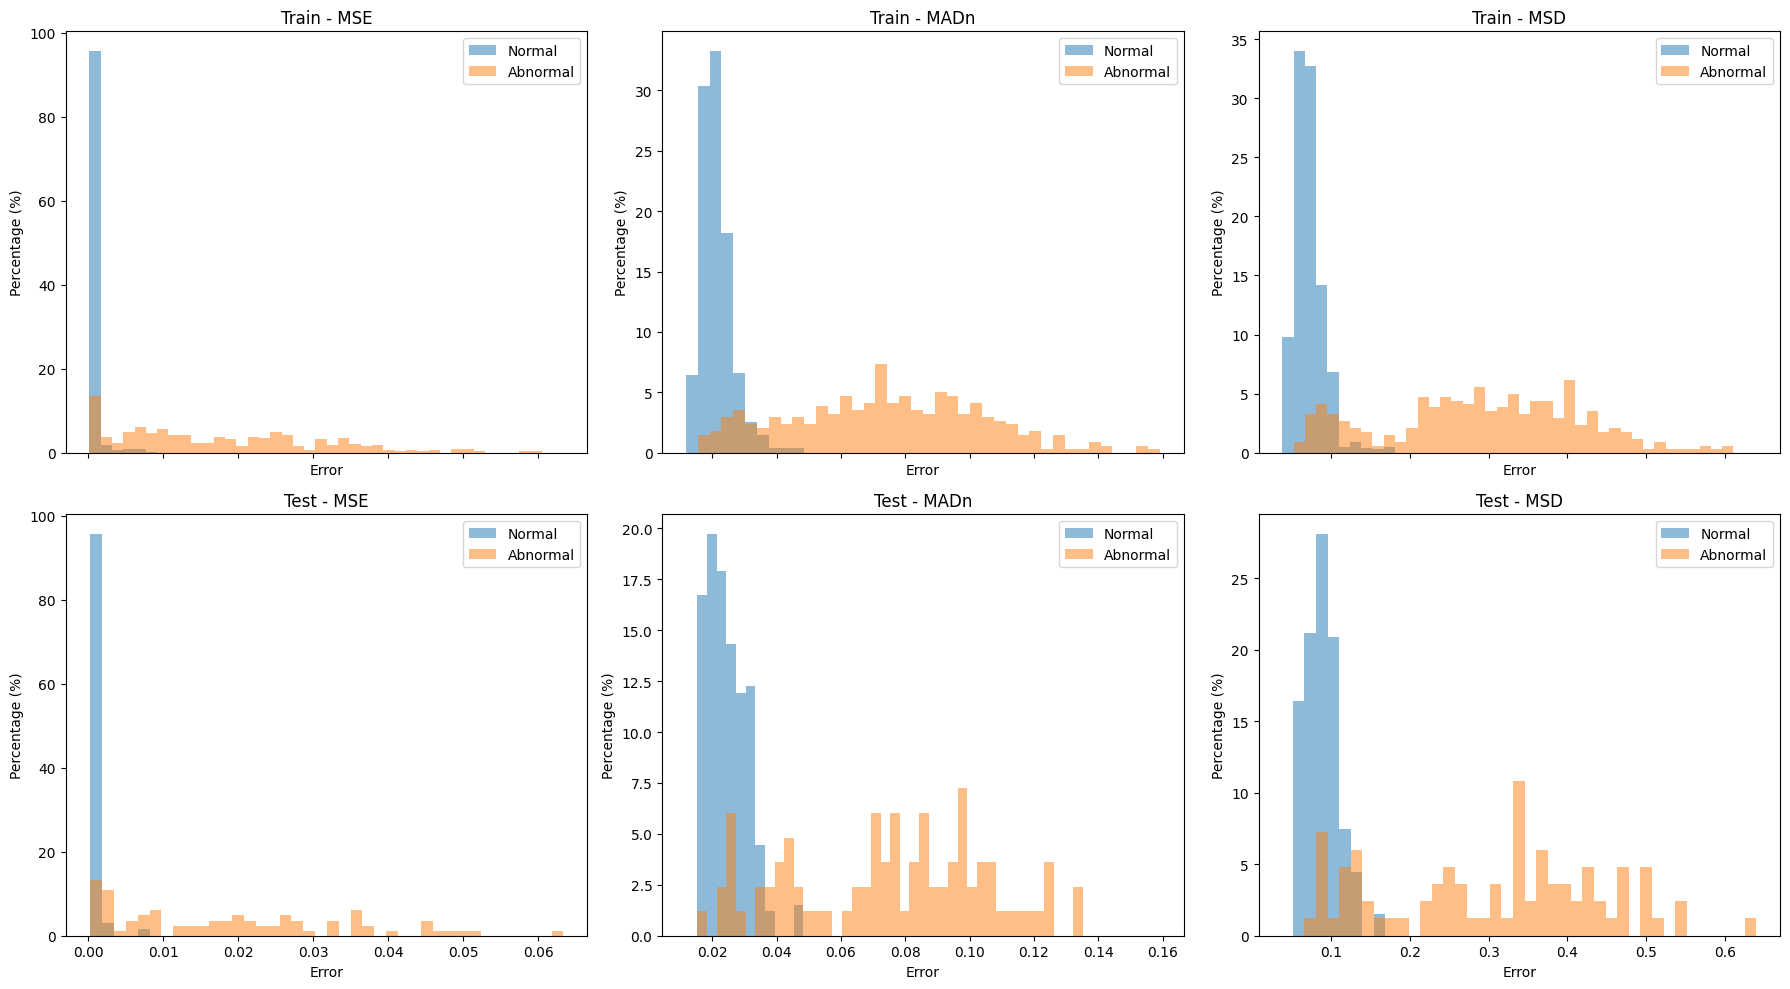

In [12]:
import numpy as np
import matplotlib.pyplot as plt

error_functions = {
    "MSE": vector_mean_squared_error,
    "MADn": vector_mean_absolute_deviation,
    "MSD": vector_mean_standard_deviation
}

# Tính error nếu chưa có
for name, func in error_functions.items():
    if name not in image_df.columns:
        image_df[name] = compute_error_once(image_df, func)

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 10),
    sharey=False,
    sharex='col'
)

dataset_configs = [
    ("Train", image_df["is_test"] == 0),
    ("Test",  image_df["is_test"] == 1)
]

for row_idx, (dataset_name, dataset_mask) in enumerate(dataset_configs):

    df_subset = image_df[dataset_mask]

    for col_idx, error_name in enumerate(error_functions.keys()):

        ax = axes[row_idx, col_idx]

        normal = df_subset.loc[
            df_subset["is_abnormal"] == 0,
            error_name
        ]

        abnormal = df_subset.loc[
            df_subset["is_abnormal"] == 1,
            error_name
        ]

        # dùng chung bins
        bins = np.histogram_bin_edges(
            np.concatenate([normal, abnormal]),
            bins=40
        )

        # histogram theo %
        weights_normal = (
            np.ones(len(normal)) * 100 / len(normal)
            if len(normal) > 0 else None
        )

        weights_abnormal = (
            np.ones(len(abnormal)) * 100 / len(abnormal)
            if len(abnormal) > 0 else None
        )

        ax.hist(
            normal,
            bins=bins,
            weights=weights_normal,
            alpha=0.5,
            label="Normal"
        )

        ax.hist(
            abnormal,
            bins=bins,
            weights=weights_abnormal,
            alpha=0.5,
            label="Abnormal"
        )

        ax.set_title(f"{dataset_name} - {error_name}")
        ax.set_xlabel("Error")
        ax.set_ylabel("Percentage (%)")
        ax.legend()

plt.tight_layout()
plt.show()

In [13]:
results_df = run_threshold_experiments(
    image_df,
    error_functions,
    alphas=np.arange(1.5, 4.5, 0.5)
)


ERROR FUNCTION: MSE
  alpha=1.50 → F1=0.8861, Acc=0.9569
  alpha=2.00 → F1=0.8645, Acc=0.9498
  alpha=2.50 → F1=0.8344, Acc=0.9402
  alpha=3.00 → F1=0.8344, Acc=0.9402
  alpha=3.50 → F1=0.8344, Acc=0.9402
  alpha=4.00 → F1=0.8267, Acc=0.9378

ERROR FUNCTION: MADn
  alpha=1.50 → F1=0.6016, Acc=0.7656
  alpha=2.00 → F1=0.7048, Acc=0.8517
  alpha=2.50 → F1=0.8506, Acc=0.9378
  alpha=3.00 → F1=0.8795, Acc=0.9522
  alpha=3.50 → F1=0.8861, Acc=0.9569
  alpha=4.00 → F1=0.8718, Acc=0.9522

ERROR FUNCTION: MSD
  alpha=1.50 → F1=0.5984, Acc=0.7560
  alpha=2.00 → F1=0.7103, Acc=0.8517
  alpha=2.50 → F1=0.8066, Acc=0.9163
  alpha=3.00 → F1=0.8402, Acc=0.9354
  alpha=3.50 → F1=0.8645, Acc=0.9498
  alpha=4.00 → F1=0.8497, Acc=0.9450


In [14]:
print("-------------- Best in f1 --------------")
print(results_df.sort_values("f1", ascending=False).iloc[0])

print("-------------- Best in accuracy --------------")
print(results_df.sort_values("accuracy", ascending=False).iloc[0])

print("-------------- Compare f1 of each error function --------------")
print(
    results_df.groupby("error_function")["f1"]
    .agg(["mean", "max", "std"])
    .sort_values("max", ascending=False)
)

print("-------------- Which alpha is the best? --------------")
print(
    results_df.groupby("alpha")["f1"]
    .mean()
    .sort_values(ascending=False)
)

print("-------------- Which alpha is the best in each metric? --------------")
best_alphas = (results_df
        .sort_values("f1", ascending=False)  # sort toàn bộ trước
        .groupby("error_function", as_index=False)
        .first()  # lấy row có f1 cao nhất mỗi group
        .sort_values("f1", ascending=False)  # sort lại để so sánh giữa các error function
              )
print(best_alphas)

-------------- Best in f1 --------------
error_function         MSE
alpha                  1.5
mean               0.00076
std               0.000874
threshold_min    -0.000551
threshold_max     0.002071
accuracy          0.956938
f1                0.886076
precision         0.933333
recall            0.843373
r2                0.729401
Name: 0, dtype: object
-------------- Best in accuracy --------------
error_function         MSE
alpha                  1.5
mean               0.00076
std               0.000874
threshold_min    -0.000551
threshold_max     0.002071
accuracy          0.956938
f1                0.886076
precision         0.933333
recall            0.843373
r2                0.729401
Name: 0, dtype: object
-------------- Compare f1 of each error function --------------
                    mean       max       std
error_function                              
MADn            0.799059  0.886076  0.118205
MSE             0.846762  0.886076  0.023325
MSD             0.778294  0.

## MSE


FIXED ALPHA EVALUATION (alpha=3)

Thresholds: min=-0.0019, max=0.0034

CLASSIFICATION RESULTS

Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal           1655             40
True Abnormal           82            341

Classification Report:
              precision    recall  f1-score   support

      Normal       0.95      0.98      0.96      1695
    Abnormal       0.90      0.81      0.85       423

    accuracy                           0.94      2118
   macro avg       0.92      0.89      0.91      2118
weighted avg       0.94      0.94      0.94      2118


Metrics:
  accuracy: 0.9424
  f1: 0.8483
  precision: 0.8950
  recall: 0.8061
  r2: 0.6396

PER-ABNORMAL PERFORMANCE
  dominant_abnormal  count  accuracy  precision  recall  f1_score  \
0            Normal   1695    0.9764        0.0  0.0000    0.0000   
1     Abrupt Change    106    0.7925        1.0  0.7925    0.8842   
2      Signal Drift     85    0.6941        1.0  0.6941    0.8194   
3      Random P

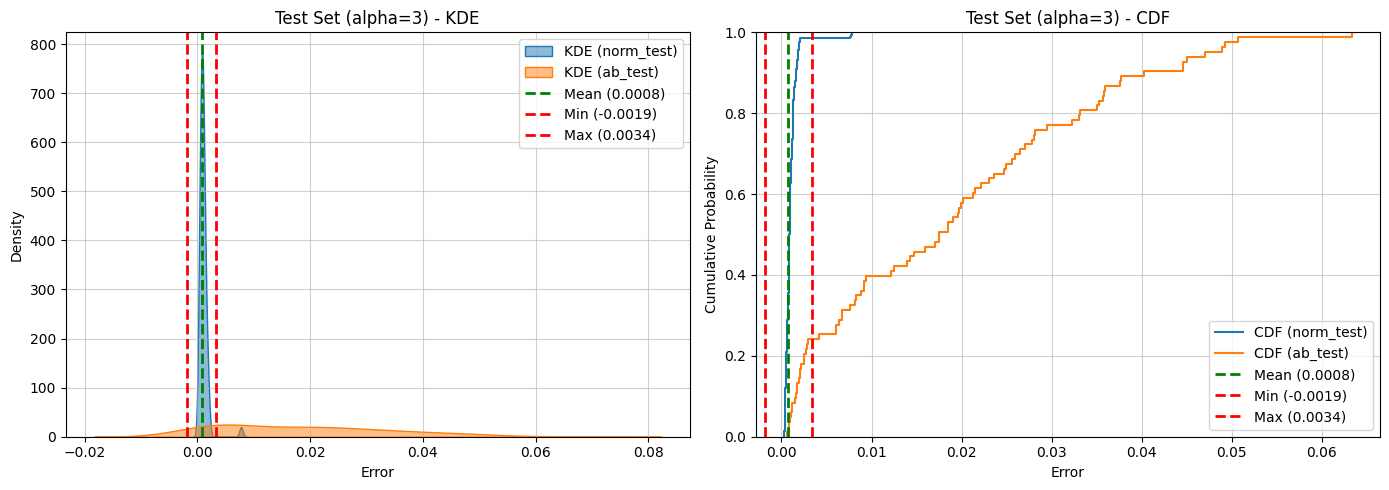

In [38]:
_ = evaluate_with_fixed_alpha(
    image_df,
    vector_mean_squared_error,
    alpha=3,
    plot=True
)

## MADn


FIXED ALPHA EVALUATION (alpha=3)

Thresholds: min=0.0064, max=0.0362

CLASSIFICATION RESULTS

Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal           1664             31
True Abnormal           57            366

Classification Report:
              precision    recall  f1-score   support

      Normal       0.97      0.98      0.97      1695
    Abnormal       0.92      0.87      0.89       423

    accuracy                           0.96      2118
   macro avg       0.94      0.92      0.93      2118
weighted avg       0.96      0.96      0.96      2118


Metrics:
  accuracy: 0.9585
  f1: 0.8927
  precision: 0.9219
  recall: 0.8652
  r2: 0.7400

PER-ABNORMAL PERFORMANCE
  dominant_abnormal  count  accuracy  precision  recall  f1_score  \
0            Normal   1695    0.9817        0.0  0.0000    0.0000   
1     Abrupt Change    106    0.9340        1.0  0.9340    0.9659   
2      Signal Drift     85    0.7765        1.0  0.7765    0.8742   
3      Random Pa

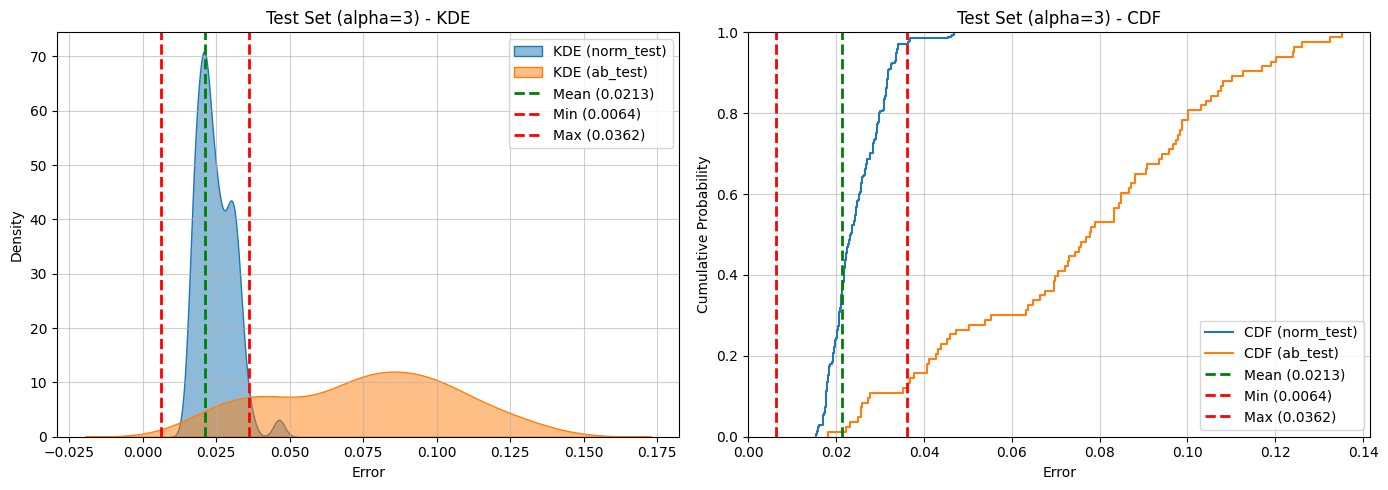

In [39]:
_ = evaluate_with_fixed_alpha(
    image_df,
    vector_mean_absolute_deviation,
    alpha=3,
    plot=True
)

## MSD


FIXED ALPHA EVALUATION (alpha=3)

Thresholds: min=0.0169, max=0.1271

CLASSIFICATION RESULTS

Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal           1660             35
True Abnormal           61            362

Classification Report:
              precision    recall  f1-score   support

      Normal       0.96      0.98      0.97      1695
    Abnormal       0.91      0.86      0.88       423

    accuracy                           0.95      2118
   macro avg       0.94      0.92      0.93      2118
weighted avg       0.95      0.95      0.95      2118


Metrics:
  accuracy: 0.9547
  f1: 0.8829
  precision: 0.9118
  recall: 0.8558
  r2: 0.7164

PER-ABNORMAL PERFORMANCE
  dominant_abnormal  count  accuracy  precision  recall  f1_score  \
0            Normal   1695    0.9794        0.0  0.0000    0.0000   
1     Abrupt Change    106    0.8962        1.0  0.8962    0.9453   
2      Signal Drift     85    0.7529        1.0  0.7529    0.8591   
3      Random Pa

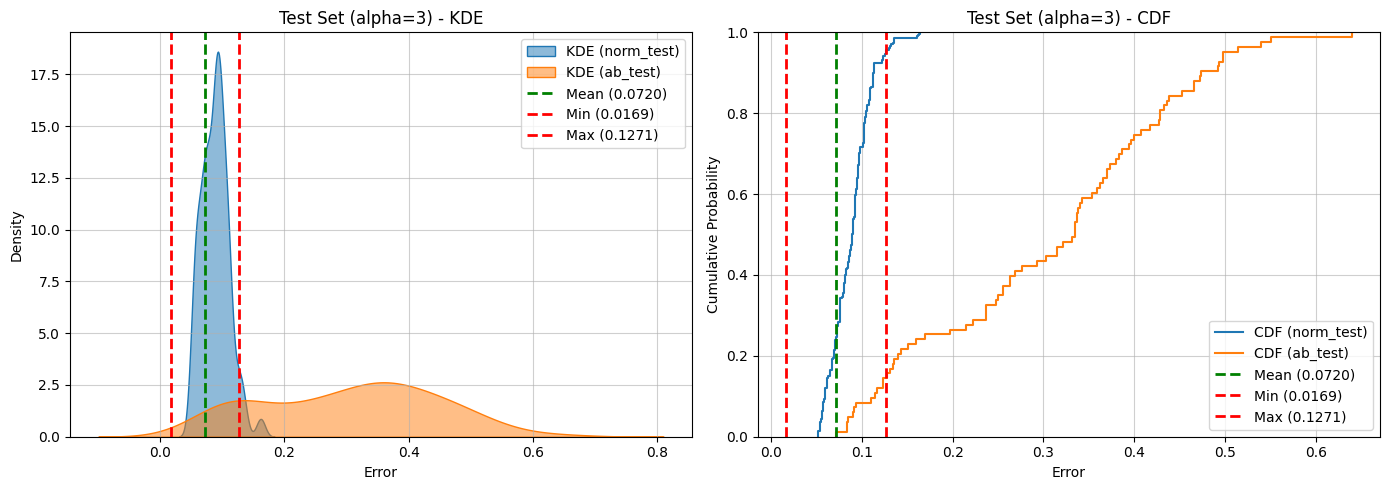

In [40]:
_ = evaluate_with_fixed_alpha(
    image_df,
    vector_mean_standard_deviation,
    alpha=3,
    plot=True
)

In [41]:
def evaluate_test_normal_all_abnormal(
    image_df,
    error_function,
    alpha=4.0
):
    from sklearn.metrics import (
        confusion_matrix,
        classification_report,
        accuracy_score,
        precision_score,
        recall_score,
        f1_score
    )

    # ==========================
    # TÍNH ERROR CHO TOÀN BỘ DATA
    # ==========================
    error_name = error_function.__name__

    df = image_df.copy()

    if error_name not in df.columns:
        df[error_name] = compute_error_once(
            df,
            error_function
        )

    # ==========================
    # THRESHOLD TỪ norm_train
    # ==========================
    norm_train = df[df["label"] == "norm_train"]

    mean_error = norm_train[error_name].mean()
    std_error = norm_train[error_name].std()

    threshold_min = mean_error - alpha * std_error
    threshold_max = mean_error + alpha * std_error

    print("="*60)
    print(f"FIXED ALPHA EVALUATION (alpha={alpha})")
    print("="*60)
    print()
    print(
        f"Thresholds: min={threshold_min:.4f}, "
        f"max={threshold_max:.4f}"
    )

    # ==========================
    # CHỈ GIỮ:
    # norm_test + tất cả abnormal
    # ==========================
    #eval_df = df[
    #    (df["label"] == "norm_test") |
    #    (df["is_abnormal"] == 1)
    #].copy()
    normal_df = df[df["label"] == "norm_test"].copy()

    abnormal_df = df[df["is_abnormal"] == 1].copy()

# lấy đúng 335 abnormal
    abnormal_df = abnormal_df.sample(n=335, random_state=42)

# ghép lại
    eval_df = pd.concat([normal_df, abnormal_df]).sample(frac=1, random_state=42).reset_index(drop=True)
    # ==========================
    # PREDICTION
    # ==========================
    eval_df["Pred_Label"] = np.where(
        (eval_df[error_name] < threshold_min) |
        (eval_df[error_name] > threshold_max),
        "Abnormal",
        "Normal"
    )

    y_true = eval_df["True_Label"]
    y_pred = eval_df["Pred_Label"]

    # ==========================
    # CONFUSION MATRIX
    # ==========================
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=["Normal", "Abnormal"]
    )

    print("\n")
    print("="*60)
    print("CLASSIFICATION RESULTS")
    print("="*60)

    print("\nConfusion Matrix:")

    print(
        f"{'':15s}"
        f"{'Pred Normal':>12s}"
        f"{'Pred Abnormal':>15s}"
    )

    print(
        f"{'True Normal':15s}"
        f"{cm[0,0]:12d}"
        f"{cm[0,1]:15d}"
    )

    print(
        f"{'True Abnormal':15s}"
        f"{cm[1,0]:12d}"
        f"{cm[1,1]:15d}"
    )

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred
    ))
# ==========================
    # PER-ABNORMAL PERFORMANCE
    # ==========================
    print("\n" + "="*60)
    print("PER-ABNORMAL PERFORMANCE")
    print("="*60)

    per_abnormal_results = []

    # Normal test
    normal_df = eval_df[eval_df["True_Label"] == "Normal"]

    normal_pred_ab = (
        normal_df["Pred_Label"] == "Abnormal"
    ).mean()

    per_abnormal_results.append({
        "dominant_abnormal": "Normal",
        "count": len(normal_df),
        "accuracy": (
            normal_df["Pred_Label"] == "Normal"
        ).mean(),
        "precision": 0.0,
        "recall": 0.0,
        "f1_score": 0.0,
        "abnormal_rate": 0.0,
        "predicted_abnormal_rate": normal_pred_ab
    })

    # Từng loại bất thường
    abnormal_types = sorted(
        eval_df.loc[
            eval_df["is_abnormal"] == 1,
            "dominant_abnormal"
        ].dropna().unique()
    )

    for ab_type in abnormal_types:

        df_ab = eval_df[
            eval_df["dominant_abnormal"] == ab_type
        ]

        count = len(df_ab)

        pred_ab_rate = (
            df_ab["Pred_Label"] == "Abnormal"
        ).mean()

        # Với từng loại abnormal,
        # accuracy = recall
        accuracy = pred_ab_rate

        precision = 1.0 if pred_ab_rate > 0 else 0.0

        recall = pred_ab_rate

        if precision + recall > 0:
            f1 = (
                2 * precision * recall
                / (precision + recall)
            )
        else:
            f1 = 0.0

        per_abnormal_results.append({
            "dominant_abnormal": ab_type,
            "count": count,
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "f1_score": f1,
            "abnormal_rate": 1.0,
            "predicted_abnormal_rate": pred_ab_rate
        })

    per_abnormal_df = pd.DataFrame(
        per_abnormal_results
    )

    print(per_abnormal_df)
    return eval_df, per_abnormal_df

In [54]:
def evaluate_test_normal_all_abnormal(
    image_df,
    error_function,
    alpha=4.0
):
    from sklearn.metrics import (
        confusion_matrix,
        classification_report,
        accuracy_score,
        precision_score,
        recall_score,
        f1_score
    )

    # ==========================
    # TÍNH ERROR CHO TOÀN BỘ DATA
    # ==========================
    error_name = error_function.__name__

    df = image_df.copy()

    if error_name not in df.columns:
        df[error_name] = compute_error_once(
            df,
            error_function
        )

    # ==========================
    # THRESHOLD TỪ norm_train
    # ==========================
    norm_train = df[df["label"] == "norm_train"]

    mean_error = norm_train[error_name].mean()
    std_error = norm_train[error_name].std()

    threshold_min = mean_error - alpha * std_error
    threshold_max = mean_error + alpha * std_error

    print("="*60)
    print(f"FIXED ALPHA EVALUATION (alpha={alpha})")
    print("="*60)
    print()
    print(
        f"Thresholds: min={threshold_min:.4f}, "
        f"max={threshold_max:.4f}"
    )

    # ==========================
    # CHỈ GIỮ:
    # norm_test + tất cả abnormal
    # ==========================
    #eval_df = df[
    #    (df["label"] == "norm_test") |
    #    (df["is_abnormal"] == 1)
    #].copy()
    normal_df = df[df["label"] == "norm_test"].copy()

    abnormal_df = df[df["is_abnormal"] == 1].copy()

# lấy đúng 335 abnormal
    abnormal_df = abnormal_df.sample(n=335, random_state=42)

# ghép lại
    eval_df = pd.concat([normal_df, abnormal_df]).sample(frac=1, random_state=42).reset_index(drop=True)
    # ==========================
    # PREDICTION
    # ==========================
    eval_df["Pred_Label"] = np.where(
        (eval_df[error_name] < threshold_min) |
        (eval_df[error_name] > threshold_max),
        "Abnormal",
        "Normal"
    )

    y_true = eval_df["True_Label"]
    y_pred = eval_df["Pred_Label"]

    # ==========================
    # CONFUSION MATRIX
    # ==========================
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=["Normal", "Abnormal"]
    )

    print("\n")
    print("="*60)
    print("CLASSIFICATION RESULTS")
    print("="*60)

    print("\nConfusion Matrix:")

    print(
        f"{'':15s}"
        f"{'Pred Normal':>12s}"
        f"{'Pred Abnormal':>15s}"
    )

    print(
        f"{'True Normal':15s}"
        f"{cm[0,0]:12d}"
        f"{cm[0,1]:15d}"
    )

    print(
        f"{'True Abnormal':15s}"
        f"{cm[1,0]:12d}"
        f"{cm[1,1]:15d}"
    )

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred
    ))
# ==========================
    # PER-ABNORMAL PERFORMANCE
    # ==========================
    print("\n" + "="*60)
    print("PER-ABNORMAL PERFORMANCE")
    print("="*60)

    per_abnormal_results = []

    # Normal test
    normal_df = eval_df[eval_df["True_Label"] == "Normal"]

    normal_pred_ab = (
        normal_df["Pred_Label"] == "Abnormal"
    ).mean()

    per_abnormal_results.append({
        "dominant_abnormal": "Normal",
        "count": len(normal_df),
        "accuracy": (
            normal_df["Pred_Label"] == "Normal"
        ).mean(),
        "precision": 0.0,
        "recall": 0.0,
        "f1_score": 0.0,
        "abnormal_rate": 0.0,
        "predicted_abnormal_rate": normal_pred_ab
    })

    # Từng loại bất thường
    abnormal_types = sorted(
        eval_df.loc[
            eval_df["is_abnormal"] == 1,
            "dominant_abnormal"
        ].dropna().unique()
    )
    for ab_type in abnormal_types:
    
        df_ab = eval_df[
            eval_df["dominant_abnormal"] == ab_type
        ]
    
        count = len(df_ab)
    
        pred_ab_rate = (df_ab["Pred_Label"] == "Abnormal").mean()
    
        # số dự đoán đúng / sai
        correct_count = (df_ab["Pred_Label"] == df_ab["True_Label"]).sum()
        wrong_count = count - correct_count
    
        # accuracy = recall (cách bạn đang dùng)
        accuracy = pred_ab_rate
    
        precision = 1.0 if pred_ab_rate > 0 else 0.0
        recall = pred_ab_rate
    
        if precision + recall > 0:
            f1 = (2 * precision * recall) / (precision + recall)
        else:
            f1 = 0.0
    
        per_abnormal_results.append({
            "dominant_abnormal": ab_type,
            "count": count,
    
            # NEW COLUMNS
            "correct_count": int(correct_count),
            "wrong_count": int(wrong_count),
    
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "f1_score": f1,
            "abnormal_rate": 1.0,
            "predicted_abnormal_rate": pred_ab_rate
        })

    per_abnormal_df = pd.DataFrame(
        per_abnormal_results
    )

    print(per_abnormal_df)
    return eval_df, per_abnormal_df

In [33]:
df = image_df.copy()

X_test_tam = df[
    (df["label"] == "norm_test") |
    (df["is_abnormal"] == 1)
].copy()
X_test_tam.shape
X_test_tam = X_test_tam.values

# *# # # # # *1. > *# **MSE# # **

In [55]:
_ = evaluate_test_normal_all_abnormal(
    image_df,
    vector_mean_squared_error,
    alpha=3
    #alpha=2.5
)

FIXED ALPHA EVALUATION (alpha=3)

Thresholds: min=-0.0019, max=0.0034


CLASSIFICATION RESULTS

Confusion Matrix:
                Pred Normal  Pred Abnormal
True Normal             330              5
True Abnormal            65            270

Classification Report:
              precision    recall  f1-score   support

    Abnormal       0.98      0.81      0.89       335
      Normal       0.84      0.99      0.90       335

    accuracy                           0.90       670
   macro avg       0.91      0.90      0.89       670
weighted avg       0.91      0.90      0.89       670


PER-ABNORMAL PERFORMANCE
  dominant_abnormal  count  accuracy  precision    recall  f1_score  \
0            Normal    335  0.985075        0.0  0.000000  0.000000   
1     Abrupt Change     88  0.795455        1.0  0.795455  0.886076   
2             Noise     65  1.000000        1.0  1.000000  1.000000   
3      Random Patch     63  0.555556        1.0  0.555556  0.714286   
4    Sensor Failure     5

# 

# *# # # # # *1. > *# **MADn# # **

In [56]:
_ = evaluate_test_normal_all_abnormal(
    image_df,
    vector_mean_absolute_deviation,
    alpha=3
    #alpha=2.5
)

FIXED ALPHA EVALUATION (alpha=3)

Thresholds: min=0.0064, max=0.0362


CLASSIFICATION RESULTS

Confusion Matrix:
                Pred Normal  Pred Abnormal
True Normal             325             10
True Abnormal            46            289

Classification Report:
              precision    recall  f1-score   support

    Abnormal       0.97      0.86      0.91       335
      Normal       0.88      0.97      0.92       335

    accuracy                           0.92       670
   macro avg       0.92      0.92      0.92       670
weighted avg       0.92      0.92      0.92       670


PER-ABNORMAL PERFORMANCE
  dominant_abnormal  count  accuracy  precision    recall  f1_score  \
0            Normal    335  0.970149        0.0  0.000000  0.000000   
1     Abrupt Change     88  0.931818        1.0  0.931818  0.964706   
2             Noise     65  1.000000        1.0  1.000000  1.000000   
3      Random Patch     63  0.634921        1.0  0.634921  0.776699   
4    Sensor Failure     56

# *# # # #  # *1. > *# **MSD# # **  # 

In [57]:
_ = evaluate_test_normal_all_abnormal(
    image_df,
    vector_mean_standard_deviation,
    alpha=3
    #alpha=2.5
)

FIXED ALPHA EVALUATION (alpha=3)

Thresholds: min=0.0169, max=0.1271


CLASSIFICATION RESULTS

Confusion Matrix:
                Pred Normal  Pred Abnormal
True Normal             320             15
True Abnormal            49            286

Classification Report:
              precision    recall  f1-score   support

    Abnormal       0.95      0.85      0.90       335
      Normal       0.87      0.96      0.91       335

    accuracy                           0.90       670
   macro avg       0.91      0.90      0.90       670
weighted avg       0.91      0.90      0.90       670


PER-ABNORMAL PERFORMANCE
  dominant_abnormal  count  accuracy  precision    recall  f1_score  \
0            Normal    335  0.955224        0.0  0.000000  0.000000   
1     Abrupt Change     88  0.909091        1.0  0.909091  0.952381   
2             Noise     65  1.000000        1.0  1.000000  1.000000   
3      Random Patch     63  0.603175        1.0  0.603175  0.752475   
4    Sensor Failure     56

In [91]:
X_train_if = X_train_normal.reshape(
    len(X_train_normal),
    -1
)

X_test_if = X_test.reshape(
    len(X_test),
    -1
)

print(X_train_if.shape)
print(X_test_if.shape)

(1360, 16384)
(418, 16384)


In [58]:
def extract_xy_keep_normal1(df, abnormal_ratio=None, random_state=42):

    df = df.copy()

    df.loc[:, 'is_abnormal'] = 1 - df.loc[:, 'is_normal']

    df_normal = df[df["is_abnormal"] == 0]
    df_ab = df[df["is_abnormal"] == 1]


    # =========================
    # LẤY ABNORMAL
    # =========================

    if abnormal_ratio is None:
        # lấy toàn bộ abnormal
        df_ab_sampled = df_ab.copy()

    else:
        n_normal = len(df_normal)

        n_ab_sample = int(
            n_normal * abnormal_ratio /
            (1 - abnormal_ratio)
        )

        df_ab_sampled = df_ab.sample(
            n=min(n_ab_sample, len(df_ab)),
            random_state=random_state
        )


    # Ghép normal + abnormal
    df_balanced = pd.concat(
        [
            df_normal,
            df_ab_sampled
        ],
        axis=0
    )


    df_balanced = df_balanced.sample(
        frac=1,
        random_state=random_state
    ).reset_index(drop=True)


    X = np.array(
        df_balanced["Image"].tolist()
    )

    X = np.expand_dims(
        X,
        axis=-1
    )

    y = np.array(
        df_balanced["is_abnormal"].tolist()
    )


    df_balanced["Image"] = list(X)

    return X, y, df_balanced

In [59]:

_, _, df_test = read_img_from_splits(df_ab, split_test, 
                                     folder=f"{dataset_path}/augmented_abnormal",
                                     exclude_sensor_failure=False)
X_test, y_test, df_test = extract_xy_keep_normal1(
    df_test,
    abnormal_ratio=None
)

print(X_test.shape)

print_dist(y_test,"Test")

(670, 128, 128, 1)
Test distribution: {np.int64(0): np.int64(335), np.int64(1): np.int64(335)}


In [118]:
X_test.shape

(670, 16384)

In [60]:
X_tam.shape


(1360, 128, 128, 1)

In [61]:
X_train_if = X_tam.reshape(
    len(X_tam),
    -1
)
X_test_if = X_test.reshape(
    len(X_test),
    -1
) 

print(X_train_if.shape)
print(X_test_if.shape)

(1360, 16384)
(670, 16384)


## Visualize error space

In [62]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(
    n_estimators=200,
    contamination='auto',
    random_state=42,
    n_jobs=-1
)

iso.fit(X_train_if)
pred_if = iso.predict(X_test_if)

y_pred_if = np.where(
    pred_if == 1,
    0,   # Normal
    1    # Abnormal
)

In [63]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Confusion Matrix")
print(confusion_matrix(y_test, y_pred_if))

print("\nClassification Report")
print(
    classification_report(
        y_test,
        y_pred_if,
        target_names=["Normal","Abnormal"]
    )
)

print("Accuracy :", accuracy_score(y_test,y_pred_if))
print("Precision:", precision_score(y_test,y_pred_if))
print("Recall   :", recall_score(y_test,y_pred_if))
print("F1-score :", f1_score(y_test,y_pred_if))

Confusion Matrix
[[256  79]
 [ 70 265]]

Classification Report
              precision    recall  f1-score   support

      Normal       0.79      0.76      0.77       335
    Abnormal       0.77      0.79      0.78       335

    accuracy                           0.78       670
   macro avg       0.78      0.78      0.78       670
weighted avg       0.78      0.78      0.78       670

Accuracy : 0.7776119402985074
Precision: 0.7703488372093024
Recall   : 0.7910447761194029
F1-score : 0.780559646539028


In [64]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
X_train = X_train_normal.reshape(len(X_train_normal), -1)
X_test = X_test.reshape(len(X_test), -1)

print(X_train.shape, X_test.shape)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
oc_svm = OneClassSVM(
    kernel='rbf',
    gamma='scale',
    nu=0.05   # tỷ lệ anomaly mong đợi (5%)
)

oc_svm.fit(X_train_scaled)
y_pred_train = oc_svm.predict(X_train_scaled)
y_pred_test = oc_svm.predict(X_test_scaled)
y_pred_test_binary = np.where(y_pred_test == 1, 0, 1)
print(confusion_matrix(y_test, y_pred_test_binary))

print(classification_report(
    y_test,
    y_pred_test_binary,
    target_names=['Normal', 'Abnormal']
))

(1360, 16384) (670, 16384)
[[311  24]
 [ 84 251]]
              precision    recall  f1-score   support

      Normal       0.79      0.93      0.85       335
    Abnormal       0.91      0.75      0.82       335

    accuracy                           0.84       670
   macro avg       0.85      0.84      0.84       670
weighted avg       0.85      0.84      0.84       670



In [65]:
#################import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import confusion_matrix, classification_report

# =========================
# 1. Flatten dữ liệu
# =========================

X_train = X_train_normal.reshape(len(X_train_normal), -1)
X_test = X_test.reshape(len(X_test), -1)

print("Shapes:", X_train.shape, X_test.shape)

# =========================
# 2. Chuẩn hóa dữ liệu
# =========================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# =========================
# 3. Train LOF (normal only)
# =========================

lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05,
    novelty=True   # QUAN TRỌNG để predict test set
)

lof.fit(X_train_scaled)

# =========================
# 4. Dự đoán
# =========================

# Train prediction (optional)
y_pred_train = lof.predict(X_train_scaled)
y_pred_train_binary = np.where(y_pred_train == -1, 1, 0)

# Test prediction
y_pred_test = lof.predict(X_test_scaled)
y_pred_test_binary = np.where(y_pred_test == -1, 1, 0)

# =========================
# 5. Đánh giá
# =========================

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_test_binary))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_test_binary,
        target_names=['Normal', 'Abnormal']
    )
)


Shapes: (1360, 16384) (670, 16384)
Confusion Matrix:
[[310  25]
 [ 74 261]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.81      0.93      0.86       335
    Abnormal       0.91      0.78      0.84       335

    accuracy                           0.85       670
   macro avg       0.86      0.85      0.85       670
weighted avg       0.86      0.85      0.85       670



Bắt đầu vẽ 3 biểu đồ không gian sai số 2D...


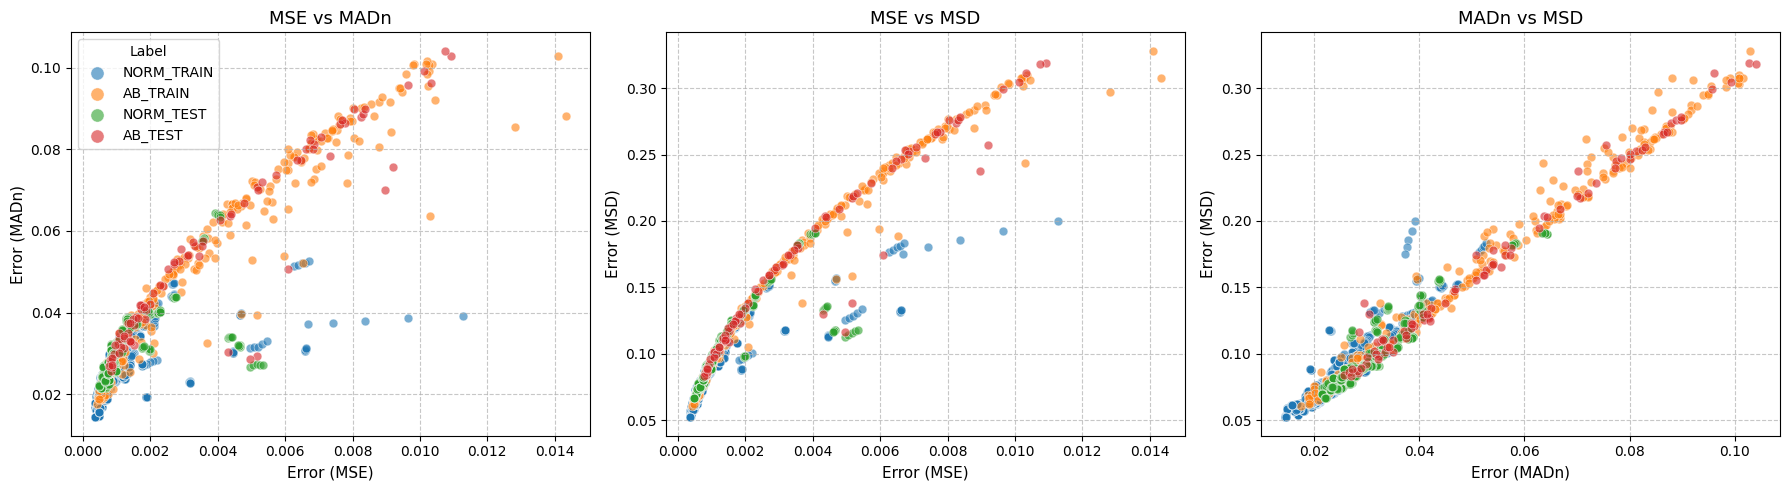

Hoàn thành trực quan hóa.


In [19]:
def visualize_error_space_2d(image_df):
    """
    Trực quan hóa không gian sai số 2D với 3 cặp chỉ số sai số, 
    vẽ thành 3 biểu đồ scatter plot nằm ngang.

    Args:
        image_df (pd.DataFrame): DataFrame chứa cột 'label'.
        mse_list (list/np.ndarray): List các giá trị sai số MSE.
        madn_list (list/np.ndarray): List các giá trị sai số MADn.
        msd_list (list/np.ndarray): List các giá trị sai số MSD.
    """
    
    # 1. Chuẩn bị DataFrame cho việc vẽ biểu đồ
    error_df = image_df.loc[:, ['MSE', 'MADn', 'MSD', 'label']]
    error_df = error_df.replace([np.inf, -np.inf], np.nan)
    error_df = error_df.dropna()
    # 2. Định nghĩa các cặp trục và nhãn
    plot_configs = [
        {'x_col': 'MSE', 'y_col': 'MADn', 'title': 'MSE vs MADn'},
        {'x_col': 'MSE', 'y_col': 'MSD', 'title': 'MSE vs MSD'},
        {'x_col': 'MADn', 'y_col': 'MSD', 'title': 'MADn vs MSD'},
    ]
    
    # Lấy các nhãn và tạo bảng màu nhất quán
    unique_labels = error_df['label'].unique()
    palette = sns.color_palette("tab10", n_colors=len(unique_labels))
    color_map = dict(zip(unique_labels, palette))
    
    
    # 3. Khởi tạo Figure với 3 Subplots nằm ngang
    fig, axes = plt.subplots(1, 3, figsize=(18, 5)) # 1 hàng, 3 cột
    
    print("Bắt đầu vẽ 3 biểu đồ không gian sai số 2D...")

    # 4. Vẽ từng biểu đồ
    for i, config in enumerate(plot_configs):
        ax = axes[i]
        x_col = config['x_col']
        y_col = config['y_col']

        # Vẽ từng nhãn riêng lẻ để sử dụng màu và tạo legend chính xác
        for label in unique_labels:
            df_subset = error_df[error_df['label'] == label]
            
            ax.scatter(
                df_subset[x_col],
                df_subset[y_col],
                color=color_map[label],
                label=label.upper(),
                alpha=0.6,
                s=40, # Kích thước điểm
                edgecolors='w', # Viền trắng
                linewidths=0.5
            )

        # Cài đặt nhãn trục và tiêu đề
        ax.set_xlabel(f'Error ({x_col})', fontsize=11)
        ax.set_ylabel(f'Error ({y_col})', fontsize=11)
        ax.set_title(config['title'], fontsize=13)
        ax.grid(True, linestyle='--', alpha=0.7)
        
        # Chỉ vẽ legend cho biểu đồ đầu tiên để tránh dư thừa, 
        # do màu sắc đã nhất quán.
        if i == 0:
            ax.legend(title='Label', loc='best', markerscale=1.5)
        
    # 5. Tối ưu layout và hiển thị
    plt.tight_layout()
    plt.show()
    print("Hoàn thành trực quan hóa.")

image_df['MSE'] = compute_error_once(image_df, vector_mean_squared_error)
image_df['MADn'] = compute_error_once(image_df, vector_mean_absolute_deviation)
image_df['MSD'] = compute_error_once(image_df, vector_mean_standard_deviation)

visualize_error_space_2d(image_df)

# AE + OneClassSVM

"Although One-Class SVM is trained using only normal data, a validation set containing both normal and abnormal samples is used to tune hyperparameters and evaluate detection capability."

In [20]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.svm import OneClassSVM, SVC
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from xgboost import XGBClassifier


def prepare_data(image_df, val_ratio=0.2, random_state=42):
    """
    Input:
        image_df: DataFrame có các cột:
            - is_abnormal (y)
            - is_test (split)
            - MSE, MADn, MSD (features)

    Output:
        X_train, y_train, X_val, y_val, X_test, y_test
    """

    df = image_df.copy()

    # ===== Features & label =====
    base = image_df[['MSE', 'MADn', 'MSD']].values
    # latent = np.vstack(image_df['latent_vector'].values)
    
    # # Nối lại thành matrix cuối
    # X = np.hstack([base, latent]).astype(np.float32)
    X = base.astype(np.float32)
    y = df['is_abnormal'].values.astype(int)

    # ===== Clean data =====
    X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)

    # ===== Split train / test =====
    train_mask = df['is_test'] == 0
    test_mask  = df['is_test'] == 1

    X_train_full = X[train_mask]
    y_train_full = y[train_mask]

    X_test = X[test_mask]
    y_test = y[test_mask]

    # ===== Split train → train + val =====
    if len(np.unique(y_train_full)) > 1:
        X_train, X_val, y_train, y_val = train_test_split(
            X_train_full, y_train_full,
            test_size=val_ratio,
            stratify=y_train_full,
            random_state=random_state
        )
    else:
        # fallback nếu train chỉ có 1 class
        X_train, X_val, y_train, y_val = train_test_split(
            X_train_full, y_train_full,
            test_size=val_ratio,
            random_state=random_state
        )

    # ===== Scale =====
    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_val   = scaler.transform(X_val)
    X_test  = scaler.transform(X_test)

    return X_train, y_train, X_val, y_val, X_test, y_test
    
def build_model(model_type, params):

    if model_type == "ocsvm":
        return OneClassSVM(kernel='rbf', **params)

    elif model_type == "isolation_forest":
        return IsolationForest(random_state=42, **params)
    
    elif model_type == "random_forest":
        return RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
            **params
    )
    elif model_type == "svm":
        return SVC(
            probability=True,
            class_weight="balanced",
            **params
        )
    elif model_type == "xgboost":
        return XGBClassifier(
            scale_pos_weight=params.get("scale_pos_weight", 1),
            eval_metric='logloss',
            **params
        )
    elif model_type == "mlp":
        return MLPClassifier(max_iter=300, **params)

    else:
        raise ValueError("Unsupported model")
        
def train(model, model_type, X_train, y_train):

    if model_type in ["ocsvm"]:
        # anomaly (normal only)
        X_train = X_train[y_train == 0]
        model.fit(X_train)

    elif model_type in ["isolation_forest"]:
        # unsupervised
        model.fit(X_train)

    else:
        # supervised
        model.fit(X_train, y_train)

    return model
    
def predict_and_score(model, model_type, X):

    if model_type == "ocsvm":
        preds = model.predict(X)  # 1 / -1
        scores = -model.decision_function(X)

        y_pred = np.where(preds == 1, 0, 1)

    elif model_type == "isolation_forest":
        preds = model.predict(X)
        scores = -model.score_samples(X)

        y_pred = np.where(preds == 1, 0, 1)

    elif model_type in ["random_forest", "svm", "xgboost", "mlp"]:

        prob = model.predict_proba(X)

        if prob.shape[1] == 1:
            scores = np.zeros(len(X))
            y_pred = np.zeros(len(X))
        else:
            scores = prob[:, 1]
            y_pred = (scores > 0.5).astype(int)

    else:
        raise ValueError("Unsupported model")

    return y_pred, scores
    
from sklearn.metrics import average_precision_score, average_precision_score, f1_score, accuracy_score
import pandas as pd


def evaluate(model, model_type, X, y, name="Set"):

    y_pred, scores = predict_and_score(model, model_type, X)

    # ===== Metrics =====
    acc = accuracy_score(y, y_pred)

    pr_auc = None
    f1 = None

    if len(np.unique(y)) > 1:
        pr_auc = average_precision_score(y, scores)
        f1 = f1_score(y, y_pred)

    # ===== Print =====
    cm = confusion_matrix(y, y_pred, labels=[0, 1])

    print("\n" + "="*50)
    print(f"{name.upper()} - {model_type.upper()}")
    print("="*50)

    print(pd.DataFrame(
        cm,
        index=['True Normal', 'True Abnormal'],
        columns=['Pred Normal', 'Pred Abnormal']
    ))

    print("\nClassification Report:")
    print(classification_report(y, y_pred, target_names=['Normal', 'Abnormal'], zero_division=0))

    print(f"Accuracy: {acc:.4f}")
    print(f"PR-AUC : {pr_auc}")
    print(f"F1-score: {f1}")

    return {
        "acc": acc,
        "pr_auc": pr_auc,
        "f1": f1
    }
    
def evaluate_all(model, model_type,
                 X_train, y_train,
                 X_val, y_val,
                 X_test, y_test):

    results = {}

    results["Train"] = evaluate(model, model_type, X_train, y_train, "Train")
    results["Val"]   = evaluate(model, model_type, X_val, y_val, "Validation")
    results["Test"]  = evaluate(model, model_type, X_test, y_test, "Test")

    return results

import itertools

def grid_search(model_type, param_grid,
                X_train, y_train,
                X_val, y_val):

    import itertools
    from sklearn.metrics import average_precision_score

    keys = list(param_grid.keys())
    combos = list(itertools.product(*param_grid.values()))

    best_score = -np.inf
    best_model = None
    best_params = None

    for values in combos:
        params = dict(zip(keys, values))

        model = build_model(model_type, params)
        model = train(model, model_type, X_train, y_train)

        _, scores = predict_and_score(model, model_type, X_val)

        if len(np.unique(y_val)) < 2:
            continue

        pr_auc = average_precision_score(y_val, scores)

        print(f"{model_type} | {params} → {pr_auc:.4f}")

        if pr_auc > best_score:
            best_score = pr_auc
            best_model = model
            best_params = params

    return best_model, best_params

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

def plot_boundary(model, model_type, X_train, y_train, X_val=None, y_val=None):

    pca = PCA(n_components=2)
    X_train_2d = pca.fit_transform(X_train)

    xx, yy = np.meshgrid(
        np.linspace(X_train_2d[:,0].min()-1, X_train_2d[:,0].max()+1, 200),
        np.linspace(X_train_2d[:,1].min()-1, X_train_2d[:,1].max()+1, 200)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_orig = pca.inverse_transform(grid)

    _, scores = predict_and_score(model, model_type, grid_orig)
    Z = scores.reshape(xx.shape)

    plt.figure()
    plt.contourf(xx, yy, Z > 0, alpha=0.3)
    plt.contour(xx, yy, Z, levels=[0])

    plt.scatter(X_train_2d[:,0], X_train_2d[:,1], label="Train")

    if X_val is not None:
        X_val_2d = pca.transform(X_val)
        for label in [0, 1]:
            subset = X_val_2d[y_val == label]
            plt.scatter(subset[:,0], subset[:,1], label=label)

    plt.legend()
    plt.title("Decision Boundary")
    plt.show()

In [21]:
# ===== Prepare =====
X_train, y_train, X_val, y_val, X_test, y_test = prepare_data(image_df)
print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

def show_dist(y, name):
    unique, counts = np.unique(y, return_counts=True)
    print(f"{name}:", dict(zip(unique, counts)))

show_dist(y_train, "Train")
show_dist(y_val, "Val")
show_dist(y_test, "Test")

Train: (1354, 3) (1354,)
Val  : (339, 3) (339,)
Test : (425, 3) (425,)
Train: {0: 1084, 1: 270}
Val: {0: 271, 1: 68}
Test: {0: 340, 1: 85}


In [22]:
ocsvm_grid = {
    "nu": [0.01, 0.03, 0.05, 0.1],
    "gamma": [1e-4, 1e-3, 1e-2]
}

best_ocsvm, best_params_ocsvm = grid_search(
    "ocsvm",
    ocsvm_grid,
    X_train[y_train==0], y_train[y_train==0],
    X_val, y_val
)
print(best_params_ocsvm)

ocsvm | {'nu': 0.01, 'gamma': 0.0001} → 0.4001
ocsvm | {'nu': 0.01, 'gamma': 0.001} → 0.3950
ocsvm | {'nu': 0.01, 'gamma': 0.01} → 0.4050
ocsvm | {'nu': 0.03, 'gamma': 0.0001} → 0.4904
ocsvm | {'nu': 0.03, 'gamma': 0.001} → 0.4942
ocsvm | {'nu': 0.03, 'gamma': 0.01} → 0.4974
ocsvm | {'nu': 0.05, 'gamma': 0.0001} → 0.5023
ocsvm | {'nu': 0.05, 'gamma': 0.001} → 0.5023
ocsvm | {'nu': 0.05, 'gamma': 0.01} → 0.5039
ocsvm | {'nu': 0.1, 'gamma': 0.0001} → 0.5519
ocsvm | {'nu': 0.1, 'gamma': 0.001} → 0.5527
ocsvm | {'nu': 0.1, 'gamma': 0.01} → 0.5538
{'nu': 0.1, 'gamma': 0.01}



TRAIN - OCSVM
               Pred Normal  Pred Abnormal
True Normal            976            108
True Abnormal          124            146

Classification Report:
              precision    recall  f1-score   support

      Normal       0.89      0.90      0.89      1084
    Abnormal       0.57      0.54      0.56       270

    accuracy                           0.83      1354
   macro avg       0.73      0.72      0.73      1354
weighted avg       0.82      0.83      0.83      1354

Accuracy: 0.8287
PR-AUC : 0.6290012247929613
F1-score: 0.5572519083969466

VALIDATION - OCSVM
               Pred Normal  Pred Abnormal
True Normal            236             35
True Abnormal           34             34

Classification Report:
              precision    recall  f1-score   support

      Normal       0.87      0.87      0.87       271
    Abnormal       0.49      0.50      0.50        68

    accuracy                           0.80       339
   macro avg       0.68      0.69      0.68   

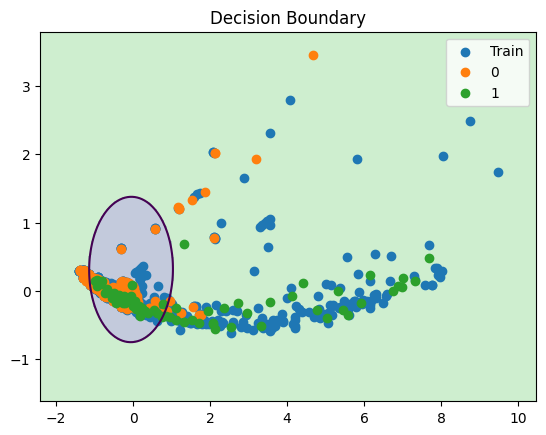

In [23]:
# ===== Train =====
params = {
    "nu": 0.1,
    "gamma": 0.01
}
model = build_model("ocsvm", params)
model = train(model, "ocsvm", X_train, y_train)

# ===== Evaluate =====
results = evaluate_all(
    model, "ocsvm",
    X_train, y_train,
    X_val, y_val,
    X_test, y_test
)

# ===== Visualization =====
plot_boundary(model, "ocsvm", X_train, y_train, X_val, y_val)

# Benchmark

In [24]:
  
def run_benchmark(X_train, y_train, X_val, y_val, X_test, y_test):
    models_config = {
        "ocsvm": {
            "nu": [0.01, 0.03, 0.05, 0.1],
            "gamma": [1e-4, 1e-3, 1e-2, 1e-1]
        },
        "isolation_forest": {
            "n_estimators": [100, 200],
            "contamination": [0.01, 0.03, 0.05, 0.1],
            "max_samples": ["auto", 0.8]
        },
        "random_forest": {
            "n_estimators": [100, 200],
            "max_depth": [None, 5, 10, 20],
            "min_samples_split": [2, 5]
        },
        "svm": {
            "C": [0.1, 1, 10],
            "gamma": ["scale", 0.01, 0.001],
            "kernel": ["rbf"]
        },
        "xgboost": {
            "n_estimators": [100, 200],
            "max_depth": [3, 5, 7],
            "learning_rate": [0.01, 0.1],
            "subsample": [0.8, 1.0]
        },
        "mlp": {
            "hidden_layer_sizes": [(64,), (128,), (128,64)],
            "alpha": [1e-4, 1e-3],
            "learning_rate_init": [1e-3, 1e-2]
        }
    }
    results_summary = {}

    # =========================================================
    # ===== 1. ML MODELS ======================================
    # =========================================================
    for model_type, grid in models_config.items():

        print("\n" + "="*60)
        print(f"MODEL: {model_type}")
        print("="*60)

        best_model, best_params = grid_search(
            model_type, grid,
            X_train, y_train,
            X_val, y_val
        )

        results = evaluate_all(
            best_model, model_type,
            X_train, y_train,
            X_val, y_val,
            X_test, y_test
        )

        results_summary[model_type] = {
            "params": best_params,
            "metrics": results   # 🔥 lưu full train/val/test
        }
    return results_summary

def print_benchmark(results, sort_by="f1"):

    print("\nFINAL BENCHMARK (TEST SET)")
    print("="*80)

    rows = []

    for model, res in results.items():
        test_metrics = res["metrics"]["Test"]

        rows.append({
            "model": model,
            "acc": test_metrics["acc"],
            "pr_auc": test_metrics["pr_auc"],
            "f1": test_metrics["f1"]
        })

    df = pd.DataFrame(rows)

    df = df.sort_values(by=sort_by, ascending=False)

    print(df.to_string(index=False))

In [25]:
results = run_benchmark(
    X_train, y_train,
    X_val, y_val,
    X_test, y_test
)

print_benchmark(results, sort_by="f1")


MODEL: ocsvm
ocsvm | {'nu': 0.01, 'gamma': 0.0001} → 0.4001
ocsvm | {'nu': 0.01, 'gamma': 0.001} → 0.3950
ocsvm | {'nu': 0.01, 'gamma': 0.01} → 0.4050
ocsvm | {'nu': 0.01, 'gamma': 0.1} → 0.5708
ocsvm | {'nu': 0.03, 'gamma': 0.0001} → 0.4904
ocsvm | {'nu': 0.03, 'gamma': 0.001} → 0.4942
ocsvm | {'nu': 0.03, 'gamma': 0.01} → 0.4974
ocsvm | {'nu': 0.03, 'gamma': 0.1} → 0.5413
ocsvm | {'nu': 0.05, 'gamma': 0.0001} → 0.5023
ocsvm | {'nu': 0.05, 'gamma': 0.001} → 0.5023
ocsvm | {'nu': 0.05, 'gamma': 0.01} → 0.5039
ocsvm | {'nu': 0.05, 'gamma': 0.1} → 0.5535
ocsvm | {'nu': 0.1, 'gamma': 0.0001} → 0.5519
ocsvm | {'nu': 0.1, 'gamma': 0.001} → 0.5527
ocsvm | {'nu': 0.1, 'gamma': 0.01} → 0.5538
ocsvm | {'nu': 0.1, 'gamma': 0.1} → 0.5612

TRAIN - OCSVM
               Pred Normal  Pred Abnormal
True Normal           1074             10
True Abnormal          145            125

Classification Report:
              precision    recall  f1-score   support

      Normal       0.88      0.99      0.9

/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


mlp | {'hidden_layer_sizes': (128, 64), 'alpha': 0.001, 'learning_rate_init': 0.001} → 0.7882
mlp | {'hidden_layer_sizes': (128, 64), 'alpha': 0.001, 'learning_rate_init': 0.01} → 0.7829

TRAIN - MLP
               Pred Normal  Pred Abnormal
True Normal           1084              0
True Abnormal          134            136

Classification Report:
              precision    recall  f1-score   support

      Normal       0.89      1.00      0.94      1084
    Abnormal       1.00      0.50      0.67       270

    accuracy                           0.90      1354
   macro avg       0.94      0.75      0.81      1354
weighted avg       0.91      0.90      0.89      1354

Accuracy: 0.9010
PR-AUC : 0.7960153640162676
F1-score: 0.6699507389162561

VALIDATION - MLP
               Pred Normal  Pred Abnormal
True Normal            271              0
True Abnormal           38             30

Classification Report:
              precision    recall  f1-score   support

      Normal       0.88   

In [26]:
# This notebook originally belong to huong.nguyenthu4@hust.edu.vn 14/4/3026
# print("co2_conc that is classified as abnormal: ",y_abnormal_co2[anomalies])
# print(f"index of abnormals: {anomalies}")
# plt.hist(y_abnormal_co2[np.where(predictions != -1)], alpha=0.75, label='Normal')
# plt.hist(y_abnormal_co2[np.where(predictions == -1)], alpha=0.75, label='Abnormal')
# plt.title("Predict of OneClassSVM")
# plt.legend()
# plt.show()

# Dynamic threshold

In [27]:
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import classification_report, confusion_matrix

def calculate_error_only(image_df, cal_error_function):
    """
    Chỉ tính error cho từng sample
    """
    original_images_list = image_df['original_image'].tolist()
    reconstructed_images_list = image_df['reconstructed_image'].tolist()
    
    all_errors = cal_error_function(original_images_list, reconstructed_images_list)
    image_df['error'] = all_errors
    
    return image_df

def train_dynamic_threshold_model(image_df, alpha=0.95):
    """
    Train quantile regression model để học threshold động
    """
    
    # ⚠️ chỉ dùng norm_train
    df_train = image_df[image_df['label'] == 'norm_train']

    X = np.hstack([
        df_train[['MSE', 'MADn', 'MSD']].values,
        np.vstack(df_train['latent_vector'].values)
    ])
    
    # X = df_train[['MSE', 'MADn', 'MSD']].values      
    y = df_train['error'].values

    model = GradientBoostingRegressor(
        loss='quantile',
        alpha=alpha,
        n_estimators=200,
        max_depth=3,
        random_state=42
    )

    model.fit(X, y)

    return model

def predict_dynamic_threshold(image_df, model, margin=0.0):
    """
    Predict label bằng threshold động
    """
    
    X = np.hstack([
        image_df[['MSE', 'MADn', 'MSD']].values,
        np.vstack(image_df['latent_vector'].values)
    ])
    # X = image_df[['MSE', 'MADn', 'MSD']].values      

    # Threshold riêng từng sample
    thresholds = model.predict(X)

    # Classification
    image_df['Predicted_Label'] = np.where(
        image_df['error'] > (thresholds + margin),
        'Abnormal',
        'Normal'
    )

    return image_df, thresholds

def evaluate_dynamic(image_df, log = False):
    cm = confusion_matrix(
        image_df['True_Label'],
        image_df['Predicted_Label'],
        labels=['Normal', 'Abnormal']
    )

    if log:
        print("\n" + "="*50)
        print("DYNAMIC THRESHOLD RESULTS")
        print("="*50)
    
        print("\nConfusion Matrix:")
        print(pd.DataFrame(
            cm,
            index=['True Normal', 'True Abnormal'],
            columns=['Pred Normal', 'Pred Abnormal']
        ))
    
        print("\nClassification Report:")
        print(classification_report(
            image_df['True_Label'],
            image_df['Predicted_Label'],
            labels=['Normal', 'Abnormal'],
            zero_division=0
        ))

    return cm

def run_dynamic_threshold_pipeline(image_df, cal_error_function, alpha=0.95, margin=0.0, log = False):
    """
    Pipeline hoàn chỉnh dynamic threshold
    """

    # 1. Tính error
    image_df = calculate_error_only(image_df.copy(), cal_error_function)

    # 2. Train model
    model = train_dynamic_threshold_model(image_df, alpha=alpha)

    # 3. Predict
    image_df, thresholds = predict_dynamic_threshold(image_df, model, margin=margin)

    # 4. Evaluate
    cm = evaluate_dynamic(image_df, log)

    return image_df, thresholds, model

from sklearn.metrics import f1_score

def tune_alpha(image_df, cal_error_function, alphas):
    best_alpha = None
    best_f1 = -1

    for alpha in alphas:
        df, _, _ = run_dynamic_threshold_pipeline(
            image_df.copy(),
            cal_error_function,
            alpha=alpha
        )

        f1 = f1_score(
            df['True_Label'],
            df['Predicted_Label'],
            pos_label='Abnormal'
        )

        print(f"alpha={alpha:.3f} → F1={f1:.4f}")

        if f1 > best_f1:
            best_f1 = f1
            best_alpha = alpha

    print(f"\nBEST alpha = {best_alpha}, F1 = {best_f1:.4f}")
    return best_alpha

In [28]:
def build_model(model_name, params, alpha):
    if model_name == "gbr":
        return GradientBoostingRegressor(
            loss='quantile',
            alpha=alpha,
            random_state=42,
            **params
        )
    
    elif model_name == "rf":
        from sklearn.ensemble import RandomForestRegressor
        # RF không support quantile trực tiếp → dùng mean + scale
        return RandomForestRegressor(
            random_state=42,
            **params
        )
    
    elif model_name == "lgbm":
        from lightgbm import LGBMRegressor
        return LGBMRegressor(
            objective='quantile',
            alpha=alpha,
            random_state=42,
            **params
        )
    
    else:
        raise ValueError(f"Unknown model: {model_name}")

def train_dynamic_model_generic(image_df, model):
    df_train = image_df[image_df['label'] == 'norm_train']

    X = np.hstack([
        df_train[['MSE', 'MADn', 'MSD']].values,
        np.vstack(df_train['latent_vector'].values)
    ])

    # X = df_train[['MSE', 'MADn', 'MSD']].values
    y = df_train['error'].values

    model.fit(X, y)
    return model

from itertools import product
from sklearn.metrics import f1_score

def grid_search_dynamic_threshold(
    image_df,
    cal_error_function,
    model_configs,
    alphas,
    margins
):
    best_config = None
    best_f1 = -1
    results = []

    # Precompute error (IMPORTANT: tránh recompute nhiều lần)
    image_df = calculate_error_only(image_df.copy(), cal_error_function)

    for model_name, param_grid in model_configs.items():
        keys, values = zip(*param_grid.items())

        for param_comb in product(*values):
            params = dict(zip(keys, param_comb))

            for alpha in alphas:
                for margin in margins:

                    try:
                        model = build_model(model_name, params, alpha)

                        trained_model = train_dynamic_model_generic(image_df, model)

                        df_pred, _ = predict_dynamic_threshold(
                            image_df.copy(),
                            trained_model,
                            margin=margin
                        )

                        f1 = f1_score(
                            df_pred['True_Label'],
                            df_pred['Predicted_Label'],
                            pos_label='Abnormal'
                        )

                        config = {
                            "model": model_name,
                            "params": params,
                            "alpha": alpha,
                            "margin": margin,
                            "f1": f1
                        }

                        results.append(config)

                        print(f"{config}")

                        if f1 > best_f1:
                            best_f1 = f1
                            best_config = config

                    except Exception as e:
                        print(f"Skip config due to error: {e}")

    print("\nBEST CONFIG:")
    print(best_config)

    return best_config, pd.DataFrame(results)

def evaluate_best_config(
    image_df,
    cal_error_function,
    best_config,
    results_df=None,
    log=True
):
    """
    Train lại model với best_config và evaluate đầy đủ
    """

    # 1. Copy data + tính error
    df = calculate_error_only(image_df.copy(), cal_error_function)

    # 2. Build model từ best_config
    model = build_model(
        best_config["model"],
        best_config["params"],
        best_config["alpha"]
    )

    # 3. Train
    model = train_dynamic_model_generic(df, model)

    # 4. Predict
    df_pred, thresholds = predict_dynamic_threshold(
        df,
        model,
        margin=best_config["margin"]
    )

    # 5. Evaluate
    cm = evaluate_dynamic(df_pred, log=log)

    # 6. In thêm thông tin best config
    print("\nBEST CONFIG USED:")
    for k, v in best_config.items():
        print(f"{k}: {v}")

    # 7. Optional: phân tích ranking
    if results_df is not None:
        print("\nTOP 5 CONFIGS:")
        display_cols = ["model", "alpha", "margin", "f1"]
        if "params" in results_df.columns:
            display_cols.append("params")

        print(
            results_df
            .sort_values("f1", ascending=False)
            .head(5)[display_cols]
        )

    return df_pred, thresholds, model, cm

In [29]:
def pipeline_dynamic_thres(image_df, cal_error_function, alphas, model_configs, margins):
    # 1. Tune alpha
    # best_alpha = tune_alpha(
    #     image_df,
    #     cal_error_function,
    #     alphas=alphas
    # )
    best_config, results_df = grid_search_dynamic_threshold(
        image_df,
        cal_error_function,
        model_configs,
        alphas,
        margins
    )
    # 2. Run final
    # df_result, thresholds, model = run_dynamic_threshold_pipeline(
    #     image_df,
    #     cal_error_function,
    #     alpha=best_alpha,
    #     margin=0.0,
    #     log=True
    # )
    df_pred, thresholds, model, cm = evaluate_best_config(
        image_df,
        cal_error_function,
        best_config,
        results_df=results_df,
        log=True
    )
    return results_df

In [30]:
model_configs = {
    "gbr": {
        "n_estimators": [20, 50, 100],
        "max_depth": [1, 3],
        "learning_rate": [0.001, 0.05]
    },
    "rf": {
        "n_estimators": [50, 100],
        "max_depth": [None, 5]
    },
    "lgbm": {
        "n_estimators": [20, 50, 100],
        "num_leaves": [16, 32],
        "learning_rate": [0.001, 0.05]
    }
}

alphas = np.arange(0.9, 1-0.01, 0.01)
margins = [0.0, 0.001] # np.arange(0.0, 0.05, 0.01)

## MSE

In [31]:
results_df = pipeline_dynamic_thres(image_df = image_df, 
                       cal_error_function = vector_mean_squared_error,
                       alphas = alphas,
                       model_configs = model_configs,
                       margins = margins)

{'model': 'gbr', 'params': {'n_estimators': 20, 'max_depth': 1, 'learning_rate': 0.001}, 'alpha': 0.9, 'margin': 0.0, 'f1': 0.5932584269662922}
{'model': 'gbr', 'params': {'n_estimators': 20, 'max_depth': 1, 'learning_rate': 0.001}, 'alpha': 0.9, 'margin': 0.001, 'f1': 0.5648414985590778}
{'model': 'gbr', 'params': {'n_estimators': 20, 'max_depth': 1, 'learning_rate': 0.001}, 'alpha': 0.91, 'margin': 0.0, 'f1': 0.5899772209567198}
{'model': 'gbr', 'params': {'n_estimators': 20, 'max_depth': 1, 'learning_rate': 0.001}, 'alpha': 0.91, 'margin': 0.001, 'f1': 0.5627705627705627}
{'model': 'gbr', 'params': {'n_estimators': 20, 'max_depth': 1, 'learning_rate': 0.001}, 'alpha': 0.92, 'margin': 0.0, 'f1': 0.5950413223140496}
{'model': 'gbr', 'params': {'n_estimators': 20, 'max_depth': 1, 'learning_rate': 0.001}, 'alpha': 0.92, 'margin': 0.001, 'f1': 0.561046511627907}
{'model': 'gbr', 'params': {'n_estimators': 20, 'max_depth': 1, 'learning_rate': 0.001}, 'alpha': 0.93, 'margin': 0.0, 'f1': 0.

In [32]:
results_df.sort_values("f1", ascending=False).head(50)

,model,params,alpha,margin,f1
184,gbr,"{'n_estimators': 100, 'max_depth': 3, 'learnin...",0.92,0.0,0.600770
148,gbr,"{'n_estimators': 100, 'max_depth': 1, 'learnin...",0.92,0.0,0.600770
38,gbr,"{'n_estimators': 20, 'max_depth': 3, 'learning...",0.91,0.0,0.597701
368,lgbm,"{'n_estimators': 50, 'num_leaves': 16, 'learni...",0.94,0.0,0.595908
404,lgbm,"{'n_estimators': 50, 'num_leaves': 32, 'learni...",0.94,0.0,0.595908
40,gbr,"{'n_estimators': 20, 'max_depth': 3, 'learning...",0.92,0.0,0.595745
182,gbr,"{'n_estimators': 100, 'max_depth': 3, 'learnin...",0.91,0.0,0.595477
4,gbr,"{'n_estimators': 20, 'max_depth': 1, 'learning...",0.92,0.0,0.595041
112,gbr,"{'n_estimators': 50, 'max_depth': 3, 'learning...",0.92,0.0,0.593674
76,gbr,"{'n_estimators': 50, 'max_depth': 1, 'learning...",0.92,0.0,0.593674


## MADn

In [33]:
# pipeline_dynamic_thres(image_df = image_df, 
#                        cal_error_function = vector_mean_absolute_deviation,
#                        alphas = alphas,
#                        model_configs = model_configs,
#                        margins = margins)

## MSD

In [34]:
# pipeline_dynamic_thres(image_df = image_df, 
#                        cal_error_function = vector_mean_standard_deviation,
#                        alphas = alphas,
#                        model_configs = model_configs,
#                        margins = margins)

# End of file

In [78]:
def create_image_dataframe(model, encoder, image_sets: dict):
    """
    Sử dụng model đã train để dự đoán trên các tập ảnh, sau đó tạo DataFrame 
    với ảnh gốc, ảnh tái tạo và nhãn tương ứng.
    # This entire notebook belong to huong.nguyenthu4@hust.edu.vn

    Args:
        model: Model đã được huấn luyện có phương thức `.predict()`.
        image_sets (dict): Dictionary chứa các tập ảnh.
                           - key (str): Nhãn cho tập ảnh (ví dụ: 'ab_test', 'norm_test', 'norm_train').
                           - value (np.ndarray): Mảng numpy chứa các ảnh.

    Returns:
        pd.DataFrame: DataFrame với các cột ['original_image', 'reconstructed_image', 'label'].
    """
    # List để lưu các DataFrame nhỏ của từng tập
    list_of_dfs = []
    
    print("Bắt đầu dự đoán và tạo DataFrame...")
    
    # Lặp qua từng cặp (nhãn, tập ảnh) trong dictionary
    for label, original_images in image_sets.items():
        if original_images is None or len(original_images) == 0:
            print(f"Bỏ qua nhãn '{label}' vì không có dữ liệu.")
            continue

        print(f"-> Đang dự đoán cho tập '{label}' ({len(original_images)} ảnh)...")
        # 1. Dự đoán để có ảnh tái tạo
        reconstructed_images = model.predict(original_images)
        latent_vector = encoder.predict(original_images)
        
        # 2. Tạo DataFrame cho tập hiện tại
        df_temp = pd.DataFrame({
            'original_image': list(original_images),
            'reconstructed_image': list(reconstructed_images),
            'latent_vector': list(latent_vector),
            'label': label
        })
        
        # 3. Thêm DataFrame vừa tạo vào list
        list_of_dfs.append(df_temp)

    # 4. Gộp tất cả các DataFrame nhỏ thành một DataFrame lớn
    if not list_of_dfs:
        print("Cảnh báo: Không có dữ liệu nào được xử lý. Trả về DataFrame rỗng.")
        return pd.DataFrame(columns=['original_image', 'reconstructed_image', 'label'])
        
    final_df = pd.concat(list_of_dfs, ignore_index=True)
    
    print("Hoàn thành! DataFrame đã được tạo thành công.")
    return final_df

# Đưa các tập dữ liệu vào một dictionary
image_sets_to_process = {
    'ab_test': X_test[y_test == 1],
    'norm_test': X_test[y_test == 0],
    'ab_train': X_train[y_train == 1],
    'norm_train': X_train[y_train == 0]
}

# Gọi hàm để tạo DataFrame
image_df = create_image_dataframe(autoencoder, encoder, image_sets_to_process)
# Xác định nhãn Đúng (True Labels)
true_labels_map = {'ab_train': 'Abnormal', 'ab_test': 'Abnormal', 'norm_train': 'Normal', 'norm_test': 'Normal'}
image_df['True_Label'] = image_df['label'].map(true_labels_map)
image_df['is_abnormal'] = image_df['True_Label'].map({'Abnormal': 1, 'Normal': 0})
image_df['is_test'] = image_df['label'].map({'ab_train': 0, 'ab_test': 1, 
                                             'norm_train': 0, 'norm_test': 1})


image_df.head(2)

Bắt đầu dự đoán và tạo DataFrame...
-> Đang dự đoán cho tập 'ab_test' (81 ảnh)...
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 362ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
-> Đang dự đoán cho tập 'norm_test' (325 ảnh)...
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 182ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
-> Đang dự đoán cho tập 'ab_train' (325 ảnh)...
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 181ms/step
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
-> Đang dự đoán cho tập 'norm_train' (1300 ảnh)...
41/41 ━━━━━━━━━━━━━━━━━━━━ 8s 195ms/step
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step
Hoàn thành! DataFrame đã được tạo thành công.


,original_image,reconstructed_image,latent_vector,label,True_Label,is_abnormal,is_test
0,"[[[0.57254905], [0.5176471], [0.42352942], [0....","[[[0.5784063], [0.58537275], [0.59219813], [0....","[0.0, 0.06314281, 0.0, 0.074903086, 0.02405310...",ab_test,Abnormal,1,1
1,"[[[0.69803923], [0.69803923], [0.69803923], [0...","[[[0.73288774], [0.7539128], [0.7849189], [0.7...","[0.0, 0.18177767, 0.0, 0.13986373, 0.063943714...",ab_test,Abnormal,1,1


In [79]:
from sklearn.metrics import confusion_matrix, classification_report

################--------------####################
##   NOTEBOOK CREDIT                            
##     Nguyễn Thu Hương - HUST         
# ==============================================================================
# 1. HÀM TÍNH TOÁN SAI SỐ VÀ THRESHOLD
# ==============================================================================

def calculate_errors_and_threshold(image_df, cal_error_function, alpha):
    """
    Tính sai số cho từng cặp ảnh và xác định ngưỡng phân loại (threshold).
    """
    
    # Tạo cột sai số mới
    original_images_list = image_df['original_image'].tolist()
    reconstructed_images_list = image_df['reconstructed_image'].tolist()
    
    # Hàm cal_error_function tính sai số cho TẤT CẢ các cặp ảnh cùng một lúc.
    all_errors = cal_error_function(original_images_list, reconstructed_images_list)
    image_df['error'] = all_errors

    # Gộp tất cả sai số lại để tính mean và std chung
    is_normal = image_df['label'].isin(['norm_train']) #, 'norm_test']) # chỉ lấy train để tính
    norm_errors = image_df[is_normal]['error']
    mean_error = np.mean(norm_errors)
    std_error = np.std(norm_errors)
    
    # Tính ngưỡng (Threshold)
    threshold_min = mean_error - alpha * std_error
    threshold_max = mean_error + alpha * std_error
    thresholds = {
        'mean': mean_error,
        'std': std_error,
        'threshold_min': threshold_min,
        'threshold_max': threshold_max,
        'alpha': alpha
    }
    
    return image_df, thresholds

# ==============================================================================
# 2. HÀM VẼ BIỂU ĐỒ TRỰC QUAN (VISUALIZATION)
# ==============================================================================

def plot_error_distribution(image_df, thresholds):
    """
    Vẽ phân phối sai số (KDE và CDF) của từng nhãn kèm theo các đường ngưỡng.
    """
    plt.rcParams.update({
        'font.size': 18,          # Font mặc định
        'axes.titlesize': 20,     # Tiêu đề biểu đồ
        'axes.labelsize': 18,     # Nhãn trục
        'xtick.labelsize': 18,    # Font trục X
        'ytick.labelsize': 18,    # Font trục Y
        'legend.fontsize': 18     # Font chú thích
    })
    # Tính toán ngưỡng
    mean_error = thresholds['mean']
    threshold_min = thresholds['threshold_min']
    threshold_max = thresholds['threshold_max']
    
    # Xác định các nhãn duy nhất và bảng màu
    unique_labels = image_df['label'].unique()
    # Sử dụng bảng màu của seaborn, đảm bảo màu nhất quán giữa 2 biểu đồ
    palette = sns.color_palette("tab10", n_colors=len(unique_labels))
    color_map = dict(zip(unique_labels, palette))
    
    # Khởi tạo Figure với 2 Subplots
    fig, axes = plt.subplots(1, 2, figsize=(16, 6)) # 1 hàng, 2 cột
    
    # =================================================================
    # Subplot 1: Kernel Density Estimate (KDE) - Ước lượng mật độ hạt nhân
    # =================================================================
    
    ax_kde = axes[0]
    for label in unique_labels:
        data = image_df[image_df['label'] == label]['error']
        sns.kdeplot(
            data,
            label=f'KDE ({label})',
            color=color_map[label], # Dùng màu nhất quán
            fill=True,
            alpha=0.5,
            ax=ax_kde
        )
        
    # Vẽ các đường kẻ dọc cho ngưỡng trên biểu đồ KDE
    ax_kde.axvline(mean_error, color='g', linestyle='--', linewidth=2, label=f'Mean Error ({mean_error:.4f})')
    ax_kde.axvline(threshold_min, color='r', linestyle='--', linewidth=2, label=f'Threshold Min ({threshold_min:.4f})')
    ax_kde.axvline(threshold_max, color='r', linestyle='--', linewidth=2, label=f'Threshold Max ({threshold_max:.4f})')
    
    ax_kde.set_title('Distribution of Reconstruction Error (KDE)')
    ax_kde.set_xlabel('Reconstruction Error')
    ax_kde.set_ylabel('Density')
    ax_kde.legend(loc='upper right')
    ax_kde.grid(True, alpha=0.6)
    
    # =================================================================
    # Subplot 2: Cumulative Distribution Function (CDF) - Hàm phân phối tích lũy
    # =================================================================

    ax_cdf = axes[1]
    for label in unique_labels:
        data = image_df[image_df['label'] == label]['error']
        # Sử dụng ECDF (Empirical CDF) của seaborn
        sns.ecdfplot(
            data,
            label=f'CDF ({label})',
            color=color_map[label], # Dùng màu nhất quán
            ax=ax_cdf
        )
        
    # Vẽ các đường kẻ dọc cho ngưỡng trên biểu đồ CDF
    # CDF giúp dễ dàng thấy tỷ lệ dữ liệu nằm dưới/trên ngưỡng
    ax_cdf.axvline(mean_error, color='g', linestyle='--', linewidth=2, label=f'Mean Error ({mean_error:.4f})')
    ax_cdf.axvline(threshold_min, color='r', linestyle='--', linewidth=2, label=f'Threshold Min ({threshold_min:.4f})')
    ax_cdf.axvline(threshold_max, color='r', linestyle='--', linewidth=2, label=f'Threshold Max ({threshold_max:.4f})')
    
    ax_cdf.set_title('Cumulative Distribution Function (CDF)')
    ax_cdf.set_xlabel('Reconstruction Error')
    ax_cdf.set_ylabel('Cumulative Probability')
    ax_cdf.legend(loc='lower right')
    ax_cdf.grid(True, alpha=0.6)

    # Tối ưu layout và hiển thị
    plt.tight_layout()
    # Lưu ảnh 600 dpi
    plt.savefig("KDE_CDF.png", dpi=600, bbox_inches='tight')
    plt.show()

# ==============================================================================
# 3. HÀM PHÂN LOẠI VÀ TÍNH CONFUSION MATRIX
# ==============================================================================

def evaluate_classification(image_df, thresholds):
    """
    Phân loại Normal/Abnormal dựa trên ngưỡng và tính Confusion Matrix.
    
    Quy tắc:
    - Nhãn cũ ('ab_test', 'norm_train', 'norm_test') -> Nhãn đúng (True Label)
    - Phân loại bằng ngưỡng (Threshold) -> Nhãn dự đoán (Predicted Label)
    """
    
    # 2. Phân loại bằng Ngưỡng (Predicted Labels)
    threshold_min = thresholds['threshold_min']
    threshold_max = thresholds['threshold_max']
    
    # Nếu sai số nằm NGOÀI khoảng [min, max] -> Abnormal (phân loại)
    # Nếu sai số nằm TRONG khoảng [min, max] -> Normal (phân loại)
    def classify_by_threshold(error):
        if error < threshold_min or error > threshold_max:
            return 'Abnormal'
        return 'Normal'
    
    image_df['Predicted_Label'] = image_df['error'].apply(classify_by_threshold)
    
    # 3. Tính Confusion Matrix
    cm = confusion_matrix(image_df['True_Label'], image_df['Predicted_Label'], labels=['Normal', 'Abnormal'])
    
    print("\n" + "="*50)
    print("CLASSIFICATION RESULTS (Threshold-Based)")
    print("="*50)
    print("Confusion Matrix:")
    print(pd.DataFrame(cm, index=['True Normal', 'True Abnormal'], columns=['Pred Normal', 'Pred Abnormal']))
    
    print("\nClassification Report:")
    print(classification_report(image_df['True_Label'], image_df['Predicted_Label'], labels=['Normal', 'Abnormal']))
    
    return image_df, cm

# ==============================================================================
# HÀM CHÍNH (MAIN FUNCTION)
# ==============================================================================

def cal_error_n_plot(cal_error_function, image_df, alpha=1.5):
    """
    Tính toán sai số, xác định ngưỡng, vẽ biểu đồ và đánh giá phân loại Anomalies.
    
    Input: 
        cal_error_function: Hàm tính sai số (e.g., MSE, MAE).
        image_df: DataFrame chứa các cột 'original_image', 'reconstructed_image', 'label' ('ab_test', 'norm_train', 'norm_test').
        alpha: Hệ số để xác định ngưỡng: mean ± alpha*std.
        
    Output: 
        error_lists: Dictionary chứa list sai số của từng nhãn ('ab_test', 'norm_train', 'norm_test').
    """
    
    print(f"--- BẮT ĐẦU TÍNH TOÁN VỚI ALPHA = {alpha} ---")
    
    # 1. Tính toán sai số và Threshold
    image_df_with_error, thresholds = calculate_errors_and_threshold(
        image_df, cal_error_function, alpha
    )
    
    print(f"\nMean Error (tổng): {thresholds['mean']:.4f}")
    print(f"Std Dev (tổng): {thresholds['std']:.4f}")
    print(f"Threshold Range (mean ± {alpha}*std): [{thresholds['threshold_min']:.4f}, {thresholds['threshold_max']:.4f}]")
    
    # 2. Vẽ biểu đồ Visualize sai số và Threshold
    plot_error_distribution(image_df_with_error, thresholds)
    
    # 3. Đánh giá phân loại và Confusion Matrix
    image_df_classified, cm = evaluate_classification(image_df_with_error.copy(), thresholds)
    
    print("\n--- KẾT THÚC QUÁ TRÌNH ---")
    
    return image_df_with_error['error']

--- BẮT ĐẦU TÍNH TOÁN VỚI ALPHA = 3 ---

Mean Error (tổng): 0.0006
Std Dev (tổng): 0.0004
Threshold Range (mean ± 3*std): [-0.0006, 0.0018]


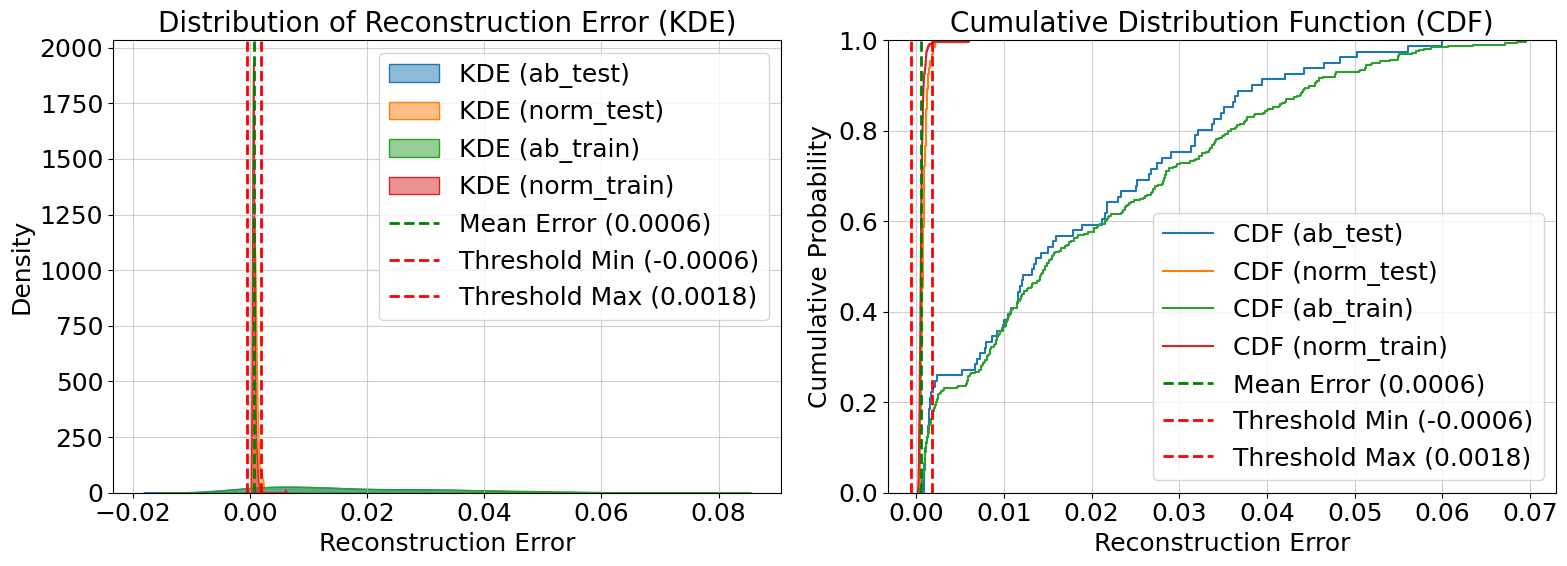


CLASSIFICATION RESULTS (Threshold-Based)
Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal           1604             21
True Abnormal           73            333

Classification Report:
              precision    recall  f1-score   support

      Normal       0.96      0.99      0.97      1625
    Abnormal       0.94      0.82      0.88       406

    accuracy                           0.95      2031
   macro avg       0.95      0.90      0.92      2031
weighted avg       0.95      0.95      0.95      2031


--- KẾT THÚC QUÁ TRÌNH ---


In [80]:
def vector_mean_squared_error(original_images, reconstructed_images):
    """
    Tính MSE cho tất cả các cặp ảnh.
    
    Input: Hai list/mảng chứa các ảnh.
    Output: Một mảng NumPy chứa MSE cho từng cặp.
    """
    
    # Chuyển list ảnh thành mảng NumPy 4D nếu cần
    X_orig = np.array(original_images)
    X_reco = np.array(reconstructed_images)
    
    # Tính lỗi bình phương cho từng pixel
    squared_error = (X_orig - X_reco) ** 2
    
    # Tính giá trị trung bình (Mean) trên các chiều của ảnh (thường là 3 chiều cuối: H, W, C)
    error_values = np.mean(squared_error, axis=(1, 2, 3))    
    return error_values
image_df['MSE'] = cal_error_n_plot(
    cal_error_function=vector_mean_squared_error, 
    image_df=image_df,
    alpha=3 # Độ rộng khoảng threshold
)


--- BẮT ĐẦU TÍNH TOÁN VỚI ALPHA = 3.5 ---

Mean Error (tổng): 0.0695
Std Dev (tổng): 0.0148
Threshold Range (mean ± 3.5*std): [0.0176, 0.1213]


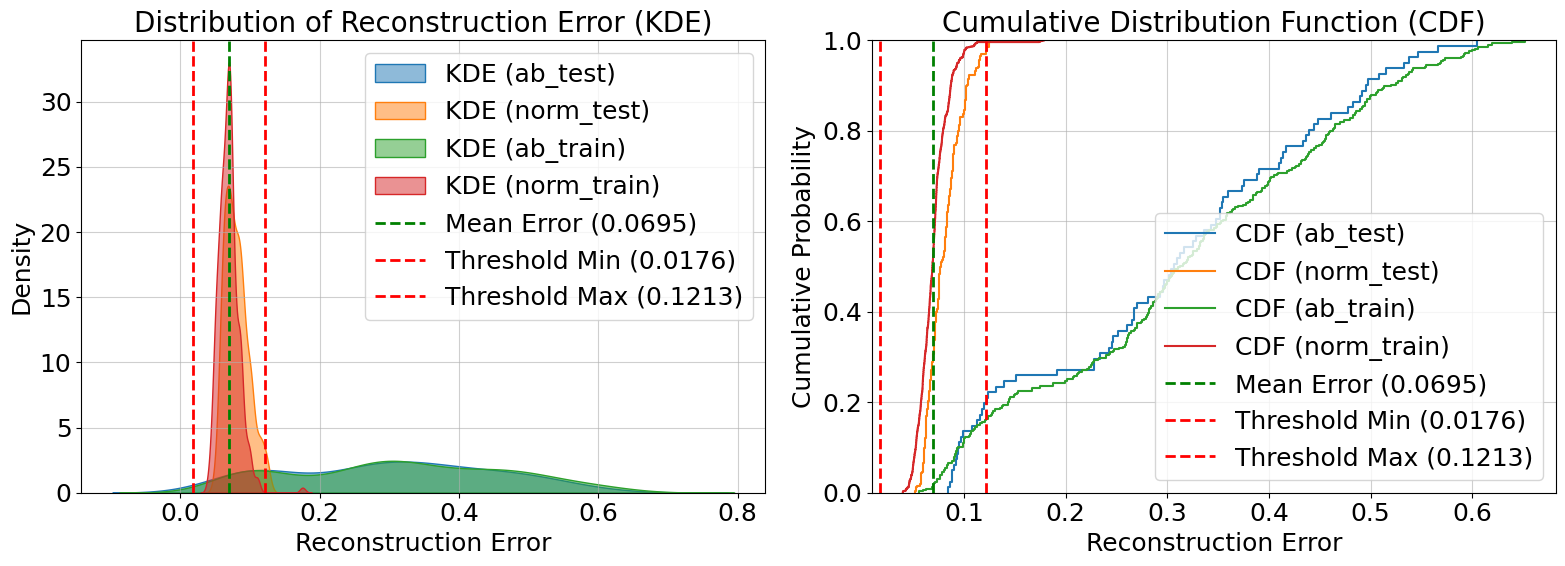


CLASSIFICATION RESULTS (Threshold-Based)
Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal           1610             15
True Abnormal           69            337

Classification Report:
              precision    recall  f1-score   support

      Normal       0.96      0.99      0.97      1625
    Abnormal       0.96      0.83      0.89       406

    accuracy                           0.96      2031
   macro avg       0.96      0.91      0.93      2031
weighted avg       0.96      0.96      0.96      2031


--- KẾT THÚC QUÁ TRÌNH ---


In [82]:
def vector_mean_standard_deviation(original_images, reconstructed_images):
    """
    Tính chỉ số sai số MSD (Mean Standard Deviation) cho từng cặp ảnh.
    
    Công thức: MSD = mean(| (true_value - predicted_value) / std(true_value) |)
    
    Lưu ý: std(true_value) được tính trên TẤT CẢ pixel của TẤT CẢ ảnh gốc
           trong batch để có một giá trị chuẩn hóa chung duy nhất (như thường thấy
           trong các nghiên cứu sử dụng MSD làm chỉ số chuẩn hóa).

    Args:
        original_images (list or np.ndarray): List/Mảng các ảnh gốc (e.g., shape (N, H, W, C)).
        reconstructed_images (list or np.ndarray): List/Mảng các ảnh tái tạo.

    Returns:
        np.ndarray: Mảng 1D chứa giá trị MSD sai số cho từng cặp ảnh.
    """
    
    # Chuyển list ảnh sang mảng NumPy để tận dụng vectorization
    X_orig = np.array(original_images)
    X_reco = np.array(reconstructed_images)
    
    # 1. Tính toán sự khác biệt pixel-by-pixel (Residuals)
    differences = X_orig - X_reco  # Shape: (N, H, W, C)
    
    # 2. Tính Độ lệch chuẩn (Standard Deviation) của TOÀN BỘ pixel ảnh gốc (std(true_value))
    # Sử dụng .std() trên toàn bộ mảng X_orig
    std_true_value = np.std(X_orig)
    
    # Kiểm tra trường hợp chia cho 0 (dữ liệu ảnh toàn là hằng số)
    if std_true_value == 0:
        print("Cảnh báo: Độ lệch chuẩn của ảnh gốc bằng 0. Trả về sai số 0.")
        return np.zeros(X_orig.shape[0])

    # 3. Chuẩn hóa sự khác biệt
    normalized_differences = differences / std_true_value
    
    # 4. Tính trị tuyệt đối
    abs_normalized_differences = np.abs(normalized_differences)
    
    # 5. Tính giá trị trung bình (Mean) của các giá trị chuẩn hóa
    # MSD = mean(|...|)
    # Tính mean trên các chiều của ảnh (thường là 3 chiều cuối: H, W, C)
    # Trả về mảng 1D có kích thước (N)
    # Giả sử ảnh có shape (N, H, W, C)
    
    # Xác định các trục cần tính mean (tất cả trừ trục batch đầu tiên)
    axes_to_mean = tuple(range(1, X_orig.ndim))
    
    msd_values = np.mean(abs_normalized_differences, axis=axes_to_mean)
        
    return msd_values

image_df['MSD'] = cal_error_n_plot(
    cal_error_function= vector_mean_standard_deviation, 
    image_df=image_df,
    alpha=3.5 # Độ rộng khoảng threshold
)

==================================================
CLASSIFICATION RESULTS (Threshold-Based)
==================================================
Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal           1601             24
True Abnormal           82            324

Classification Report:
              precision    recall  f1-score   support

      Normal       0.95      0.99      0.97      1625
    Abnormal       0.93      0.80      0.86       406

    accuracy                           0.95      2031
   macro avg       0.94      0.89      0.91      2031
weighted avg       0.95      0.95      0.95      2031
MSD:
CLASSIFICATION RESULTS (Threshold-Based) split 4
==================================================
Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal           1610             15
True Abnormal           69            337

Classification Report:
              precision    recall  f1-score   support

      Normal       0.96      0.99      0.97      1625
    Abnormal       0.96      0.83      0.89       406

    accuracy                           0.96      2031
   macro avg       0.96      0.91      0.93      2031
weighted avg       0.96      0.96      0.96      2031
